# Maintain Velocity Gait Analysis (Touch Sensors)

This notebook loads checkpoints trained using maintain_velocity task transfer,
generates rollouts, and performs gait analysis using **touch sensors** instead of contact detection:
- Video rendering
- Touch sensor data extraction (palm_L, palm_R, sole_L, sole_R)
- Force plots over time
- Threshold-based stance detection
- Gait diagram plotting

## Imports & Environment Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import json
from pathlib import Path

import imageio
import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
import orbax.checkpoint as ocp
from brax.training import distribution
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks
from scipy.signal import medfilt

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_velocity

from scamper.agent.task_transfer.maintain_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)

E0430 12:24:33.024570   90502 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0430 12:24:33.025010   90503 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0430 12:24:33.025029   90504 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]


## Configuration

Set the checkpoint path and other parameters here.

In [2]:
# Checkpoint path - UPDATE THIS to your checkpoint
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260228_120949_207733"
CHECKPOINT_STEP = 25  # None = latest step

NAME = "scratch_S5e-1"

# Rollout parameters
EPISODE_LENGTH = 1000  # Number of steps to roll out
SEED = 0

# Rendering parameters
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 480
RENDER_WIDTH = 640
RENDER_FPS = 50

# Output directory
OUTPUT_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/{NAME}"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint

Load the maintain_velocity checkpoint and determine the training mode.

In [3]:
# Load metadata to get config and determine mode
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
training_metadata = ckpt_info["training_metadata"]
ckpt_step = ckpt_info["step"]

mode = config["mode"]
ckpt_cfg = config["checkpoint_config"]

print(f"Loaded checkpoint at step: {ckpt_step}")
print(f"Training mode: {mode}")
print(f"Training metadata: {training_metadata}")

Loaded checkpoint at step: 25
Training mode: scratch
Training metadata: {'completed_timesteps': 401408000, 'eval_step': 25, 'wandb_run_id': 'S0.5_scratch_seed1_260228_120949_207733', 'run_id': '260228_120949_207733', 'mode': 'scratch'}


In [4]:
# Load frozen networks from the prior checkpoint embedded in the task transfer checkpoint
prior_checkpoint_path = config["checkpoint"]["path"]
prior_checkpoint_step = config["checkpoint"]["step"]

# Distill checkpoints use "DistillNetwork" prefix, prior checkpoints use "PriorNetwork"
step_prefix = "DistillNetwork" if mode == "distill" else "PriorNetwork"

print(f"Loading frozen networks from prior checkpoint: {prior_checkpoint_path}")
print(f"Mode: {mode}, step_prefix: {step_prefix}")

(
    encoder_params,
    prior_params,
    decoder_params,
    normalizer_params,
    _,
) = load_prior_checkpoint(
    prior_checkpoint_path, prior_checkpoint_step, step_prefix=step_prefix
)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

print(f"Latent size: {latent_size}")
print(f"Proprio size: {proprio_size}")
print(f"Action size: {action_size}")

Loading frozen networks from prior checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/prior_checkpoints/golden_rodent_prior_jax
Mode: scratch, step_prefix: PriorNetwork
Latent size: 16
Proprio size: 277
Action size: 38


## Create Environment

Create the maintain_velocity environment with the appropriate wrapper based on training mode.

In [5]:
# Create environment config from checkpoint
env_cfg = maintain_velocity.default_config()

# Set XML variant
xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.init_z = config["env"]["init_z"]
env_cfg.target_speed = config["env"]["target_speed"]

# Mirror the actuator type used at training time. Only scratch mode can opt into
# PD actuators; other modes always use torque (frozen decoder was trained with torque).
if mode == "scratch":
    env_cfg.torque_actuators = config.get("scratch", {}).get("torque_actuators", True)
else:
    env_cfg.torque_actuators = True

print(f"XML variant: {xml_variant}")
print(f"MuJoCo impl: {env_cfg.mujoco_impl}")
print(f"ctrl_dt: {env_cfg.ctrl_dt}")
print(f"Target speed: {env_cfg.target_speed}")
print(f"torque_actuators: {env_cfg.torque_actuators}")

XML variant: no-tail-collisions
MuJoCo impl: warp
ctrl_dt: 0.01
Target speed: 0.5
torque_actuators: False


In [6]:
# Create decoder inference function
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# Create base environment
base_env = maintain_velocity.MaintainVelocity(config=env_cfg)

# Wrap based on mode
if mode == "decoder_only":
    env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
elif mode == "scratch":
    env = FlatObsWrapper(base_env)
elif mode in ("prior_decoder", "distill"):
    # distill uses the same PriorDecoder wrapper; settings under config[mode]
    mode_cfg = config.get(mode, config.get("prior_decoder", {}))
    prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
    env = PriorDecoderHighLevelWrapper(
        base_env,
        prior_fn,
        decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=mode_cfg["deterministic_prior"],
        noise_logvar=mode_cfg["noise_logvar"],
    )
else:
    raise ValueError(f"Unknown mode: {mode}")

print(f"Created wrapped environment for mode: {mode}")
print(f"Action size (policy outputs): {env.action_size}")

Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-80GB" (79 GiB, sm_80, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Created wrapped environment for mode: scratch
Action size (policy outputs): 38


## Load Policy Parameters and Create Inference Function

In [7]:
# Create JIT-compiled reset and step functions
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

# Get observation shape from a reset
rng = jax.random.PRNGKey(0)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]

print(f"Observation size: {obs_size}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 7.41 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 1.74 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 1.84 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 2.07 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 4.15 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 1.80 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 1.79 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 2.68 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor ca6ca3f load on device 'cuda:0' took 

E0430 12:24:42.309774   90509 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.7 = s32[] reduce(%constant.50, %constant.137), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.


Observation size: 331


E0430 12:24:52.702588   90388 slow_operation_alarm.cc:140] The operation took 11.392945752s
Constant folding an instruction is taking > 1s:

  %reduce_sum.7 = s32[] reduce(%constant.50, %constant.137), dimensions={0}, to_apply=%region_0.4, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=10}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.


In [8]:
# Create network factory and build abstract params for loading
normalize = running_statistics.normalize
policy_action_size = env.action_size

if mode == "scratch":
    task_obs_size = obs_size - proprio_size
    decoder_hidden_layer_sizes = tuple(
        ckpt_cfg["network_config"]["decoder_layer_sizes"]
    )

    def network_factory(*args, **kwargs):
        return make_scratch_ppo_networks(
            task_obs_size=task_obs_size,
            proprio_size=proprio_size,
            action_size=action_size,
            latent_size=latent_size,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )

    dummy_net = network_factory()
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
else:
    network_factory = functools.partial(
        ppo_networks.make_ppo_networks,
        policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
        value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
    )

    dummy_net = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)

abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

# Load trained parameters
brax_params = load_task_transfer_brax_params(
    CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
)

print("Loaded policy parameters")

Loaded policy parameters


In [9]:
# Create inference function
if mode == "scratch":
    ppo_network = network_factory()
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

else:
    ppo_network = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}


jit_inference_fn = jax.jit(inference_fn)
print("Created inference function")

Created inference function


## Generate Rollout

In [10]:
# Generate rollout following pattern from logging.py
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)
rollout = [state]

print(f"Generating rollout with {EPISODE_LENGTH} steps...")
for i in range(EPISODE_LENGTH):
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    rollout.append(state)

    if (i + 1) % 100 == 0:
        print(f"  Step {i + 1}/{EPISODE_LENGTH}")

print(f"Rollout complete! {len(rollout)} states collected.")

Generating rollout with 1000 steps...
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 2.36 ms  (cached)
  Step 100/1000
  Step 200/1000
  Step 300/1000
  Step 400/1000
  Step 500/1000
  Step 600/1000
  Step 700/1000
  Step 800/1000
  Step 900/1000
  Step 1000/1000
Rollout complete! 1001 states collected.


## Save Rollout

In [26]:
import numpy as np
from pathlib import Path

ROLLOUT_SAVE_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/{NAME}"
)
ROLLOUT_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Extract state arrays to numpy
rollout_data = {
    "qpos": np.array([np.array(s.data.qpos) for s in rollout]),
    "qvel": np.array([np.array(s.data.qvel) for s in rollout]),
    "xpos": np.array([np.array(s.data.xpos) for s in rollout]),
    "sensordata": np.array([np.array(s.data.sensordata) for s in rollout]),
    "obs": np.array([np.array(s.obs) for s in rollout]),
    "reward": np.array([np.array(s.reward) for s in rollout]),
    "done": np.array([np.array(s.done) for s in rollout]),
}

run_id = Path(CHECKPOINT_PATH).name
save_path = ROLLOUT_SAVE_DIR / f"rollout_{NAME}_step{ckpt_step}_seed{SEED}_{run_id}.npz"
np.savez_compressed(save_path, **rollout_data)
print(f"Saved rollout to {save_path} ({save_path.stat().st_size / 1e6:.1f} MB)")

Saved rollout to /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/scratch_S5e-1/rollout_scratch_S5e-1_step25_seed0_260228_120949_207733.npz (2.4 MB)


## Load previous rollout

In [10]:
from types import SimpleNamespace

ROLLOUT_SAVE_DIR = Path(
    f"/home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/{NAME}"
)
run_id = Path(CHECKPOINT_PATH).name
save_path = ROLLOUT_SAVE_DIR / f"rollout_{NAME}_step{ckpt_step}_seed{SEED}_{run_id}.npz"

print(f"Loading rollout from {save_path}")
loaded = np.load(save_path)

# Get default values for fields needed by renderer but not saved in npz
_ref_state = jit_reset(jax.random.PRNGKey(99))
_default_mocap_pos = np.array(_ref_state.data.mocap_pos)
_default_mocap_quat = np.array(_ref_state.data.mocap_quat)
_default_xfrc = np.zeros_like(np.array(_ref_state.data.xfrc_applied))

# Reconstruct rollout as list of state-like objects
rollout = []
for i in range(len(loaded["qpos"])):
    data = SimpleNamespace(
        qpos=loaded["qpos"][i],
        qvel=loaded["qvel"][i],
        xpos=loaded["xpos"][i],
        sensordata=loaded["sensordata"][i],
        mocap_pos=_default_mocap_pos,
        mocap_quat=_default_mocap_quat,
        xfrc_applied=_default_xfrc,
    )
    state = SimpleNamespace(
        data=data,
        obs=loaded["obs"][i],
        reward=loaded["reward"][i],
        done=loaded["done"][i],
    )
    rollout.append(state)

num_timesteps = len(rollout)
print(f"Loaded {num_timesteps} states")
print(f"  qpos shape: {loaded['qpos'].shape}")
print(f"  sensordata shape: {loaded['sensordata'].shape}")

Loading rollout from /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/scratch_S5e-1/rollout_scratch_S5e-1_step25_seed0_260228_120949_207733.npz
Loaded 1001 states
  qpos shape: (1001, 74)
  sensordata shape: (1001, 16)


## Render Video

In [11]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_profile-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

Rendering video with camera 'close_profile-rodent'...


100%|██████████| 1001/1001 [00:06<00:00, 162.68it/s]


This browser does not support the video tag.


In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_front_L-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_front_R-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_hind_L-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

In [ ]:
# Render the rollout
print(f"Rendering video with camera '{RENDER_CAMERA}'...")

frames = env.render(
    rollout,
    camera="close_side_hind_R-rodent",
    height=RENDER_HEIGHT,
    width=RENDER_WIDTH,
)

media.show_video(frames, fps=RENDER_FPS)

## Extract Touch Sensor Data

Extract and plot the touch sensor readings (palm_L, palm_R, sole_L, sole_R) throughout the rollout.

In [11]:
# Get the MuJoCo model for sensor lookups
unwrapped_env = env
while hasattr(unwrapped_env, "_env") or hasattr(unwrapped_env, "env"):
    if hasattr(unwrapped_env, "_env"):
        unwrapped_env = unwrapped_env._env
    elif hasattr(unwrapped_env, "env"):
        unwrapped_env = unwrapped_env.env

mj_model = unwrapped_env.mj_model

# Find touch sensor indices in sensordata
touch_sensors = {}
print("Touch sensors found:")
for i in range(mj_model.nsensor):
    name = mujoco.mj_id2name(mj_model, mujoco.mjtObj.mjOBJ_SENSOR, i)
    if name and ("palm" in name.lower() or "sole" in name.lower()):
        sensor_adr = mj_model.sensor_adr[i]
        sensor_dim = mj_model.sensor_dim[i]
        touch_sensors[name] = {"idx": sensor_adr, "dim": sensor_dim}
        print(f"  {name}: sensordata[{sensor_adr}]")

# Define sensor indices for easy access
PALM_L_IDX = touch_sensors.get("palm_L-rodent", {}).get("idx", 9)
PALM_R_IDX = touch_sensors.get("palm_R-rodent", {}).get("idx", 10)
SOLE_L_IDX = touch_sensors.get("sole_L-rodent", {}).get("idx", 11)
SOLE_R_IDX = touch_sensors.get("sole_R-rodent", {}).get("idx", 12)

print(
    f"\nSensor indices: palm_L={PALM_L_IDX}, palm_R={PALM_R_IDX}, sole_L={SOLE_L_IDX}, sole_R={SOLE_R_IDX}"
)

Touch sensors found:
  palm_L-rodent: sensordata[9]
  palm_R-rodent: sensordata[10]
  sole_L-rodent: sensordata[11]
  sole_R-rodent: sensordata[12]

Sensor indices: palm_L=9, palm_R=10, sole_L=11, sole_R=12


In [12]:
# Extract touch sensor data from rollout
num_timesteps = len(rollout)

palm_L_data = np.zeros(num_timesteps)
palm_R_data = np.zeros(num_timesteps)
sole_L_data = np.zeros(num_timesteps)
sole_R_data = np.zeros(num_timesteps)

for t, state in enumerate(rollout):
    sensordata = np.array(state.data.sensordata)
    palm_L_data[t] = sensordata[PALM_L_IDX]
    palm_R_data[t] = sensordata[PALM_R_IDX]
    sole_L_data[t] = sensordata[SOLE_L_IDX]
    sole_R_data[t] = sensordata[SOLE_R_IDX]

print(f"Extracted touch sensor data for {num_timesteps} timesteps")
print(
    f"  palm_L: min={palm_L_data.min():.4f}, max={palm_L_data.max():.4f}, mean={palm_L_data.mean():.4f}"
)
print(
    f"  palm_R: min={palm_R_data.min():.4f}, max={palm_R_data.max():.4f}, mean={palm_R_data.mean():.4f}"
)
print(
    f"  sole_L: min={sole_L_data.min():.4f}, max={sole_L_data.max():.4f}, mean={sole_L_data.mean():.4f}"
)
print(
    f"  sole_R: min={sole_R_data.min():.4f}, max={sole_R_data.max():.4f}, mean={sole_R_data.mean():.4f}"
)

Extracted touch sensor data for 1001 timesteps
  palm_L: min=0.0000, max=0.7729, mean=0.0015
  palm_R: min=0.0000, max=0.6449, mean=0.0008
  sole_L: min=0.0000, max=3.7402, mean=0.0197
  sole_R: min=0.0000, max=4.4192, mean=0.3040


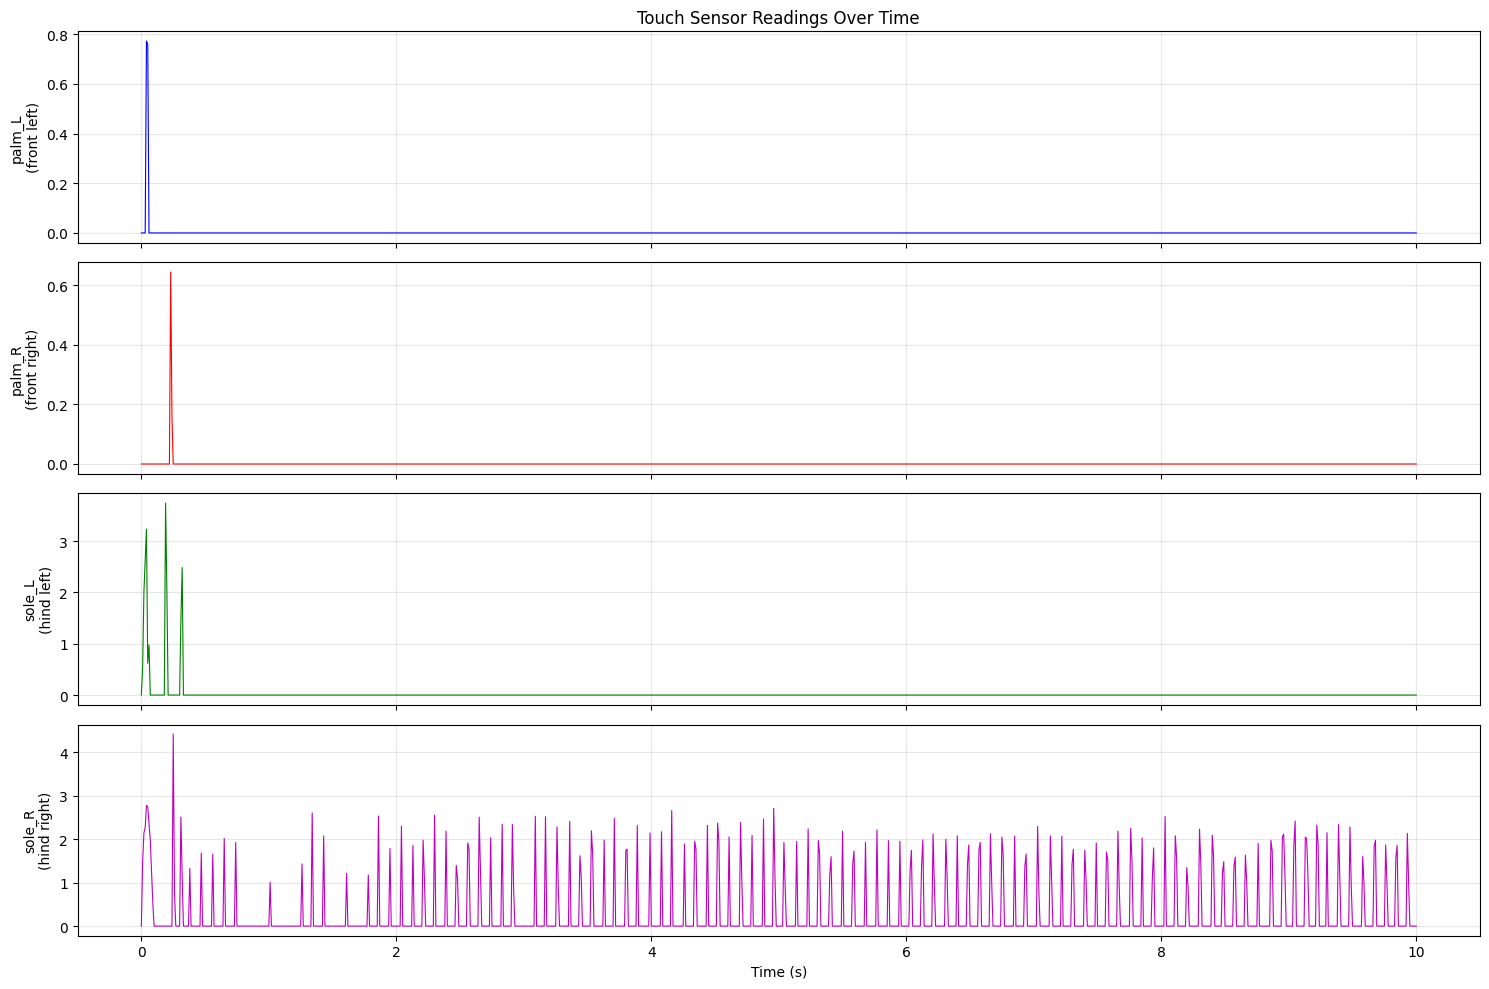

In [13]:
# Plot touch sensor data
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

timesteps = np.arange(num_timesteps)
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
time_sec = timesteps * ctrl_dt

# Palm L (front left / HL)
axes[0].plot(time_sec, palm_L_data, "b-", linewidth=0.8)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings Over Time")
axes[0].grid(True, alpha=0.3)

# Palm R (front right / HR)
axes[1].plot(time_sec, palm_R_data, "r-", linewidth=0.8)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

# Sole L (hind left / FL)
axes[2].plot(time_sec, sole_L_data, "g-", linewidth=0.8)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

# Sole R (hind right / FR)
axes[3].plot(time_sec, sole_R_data, "m-", linewidth=0.8)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

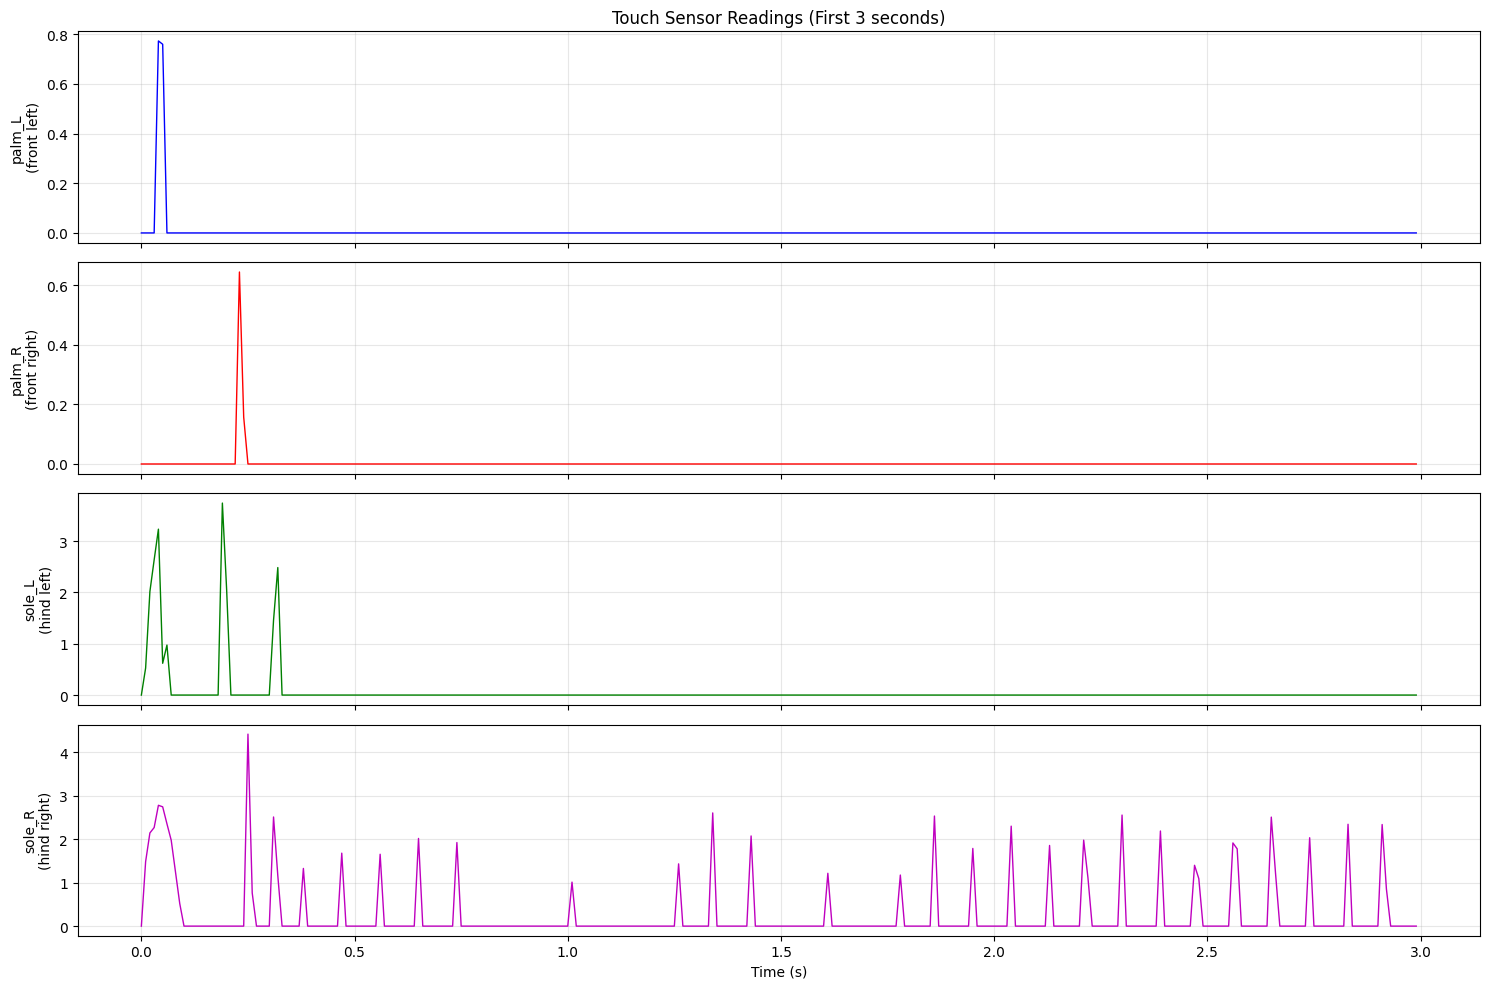

In [14]:
# Zoomed plot (first 3 seconds)
zoom_end = min(int(3.0 / ctrl_dt), num_timesteps)

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

time_zoom = time_sec[:zoom_end]

axes[0].plot(time_zoom, palm_L_data[:zoom_end], "b-", linewidth=1)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings (First 3 seconds)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_zoom, palm_R_data[:zoom_end], "r-", linewidth=1)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_zoom, sole_L_data[:zoom_end], "g-", linewidth=1)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_zoom, sole_R_data[:zoom_end], "m-", linewidth=1)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

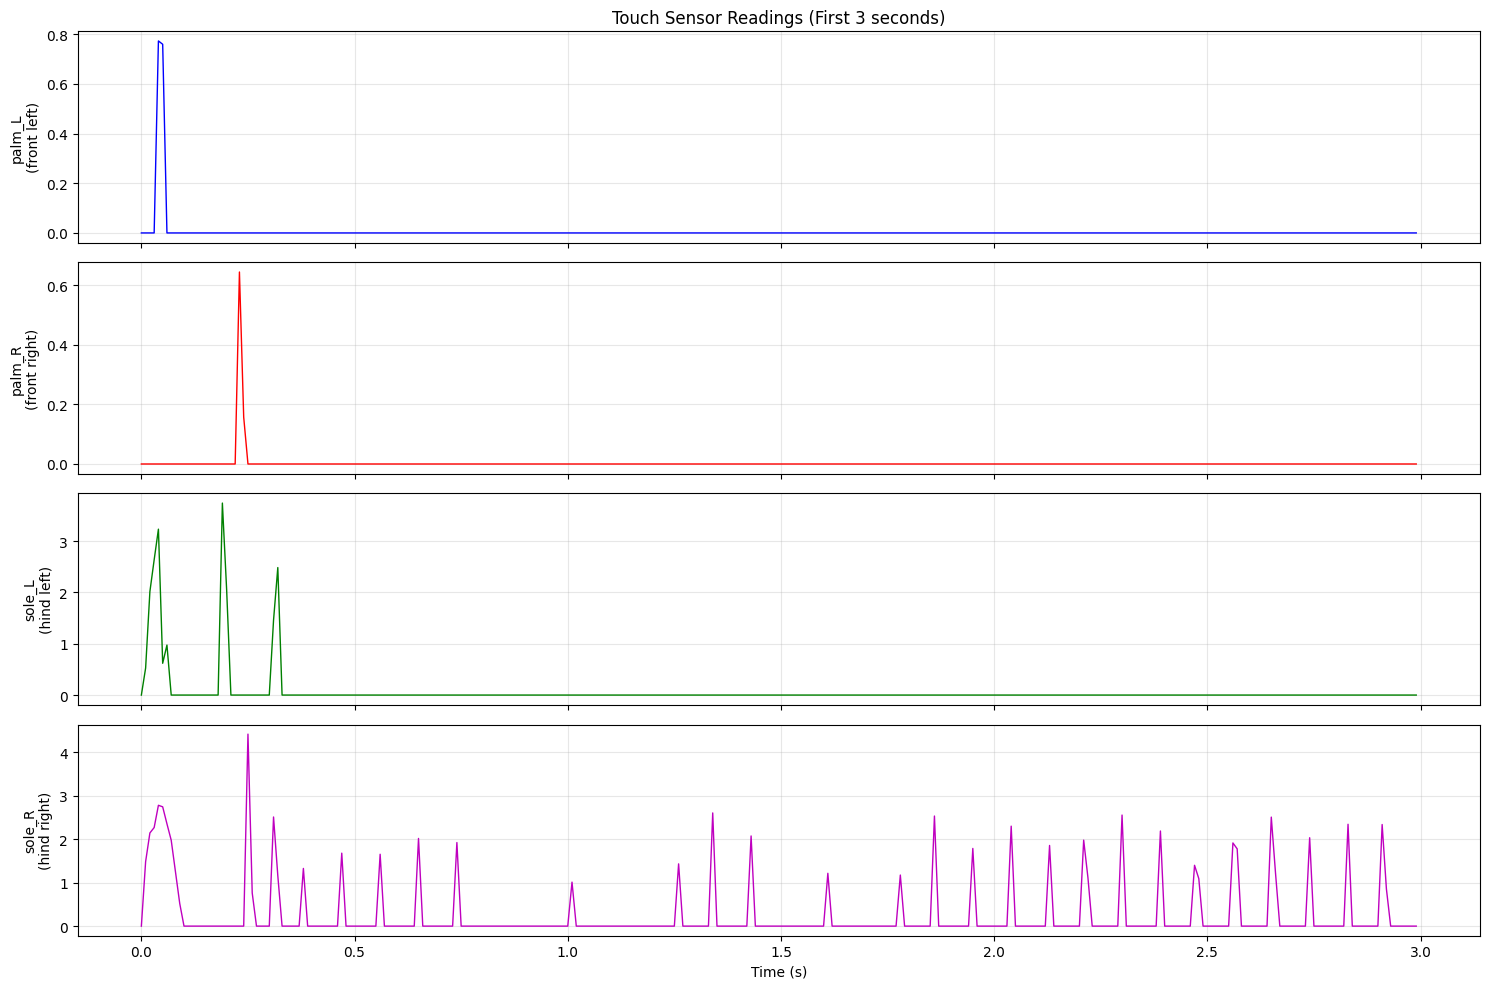

Applied median filter to raw touch sensor data


In [15]:
# Smooth raw touch sensor data in-place before thresholding
KERNEL_SIZE_PALM_L = 1
KERNEL_SIZE_PALM_R = 1
KERNEL_SIZE_SOLE_L = 1
KERNEL_SIZE_SOLE_R = 1
smooth = True

palm_L_data_smooth = medfilt(palm_L_data, kernel_size=KERNEL_SIZE_PALM_L)
palm_R_data_smooth = medfilt(palm_R_data, kernel_size=KERNEL_SIZE_PALM_R)
sole_L_data_smooth = medfilt(sole_L_data, kernel_size=KERNEL_SIZE_SOLE_L)
sole_R_data_smooth = medfilt(sole_R_data, kernel_size=KERNEL_SIZE_SOLE_R)

# Zoomed plot (first 3 seconds)
zoom_end = min(int(3.0 / ctrl_dt), num_timesteps)

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

time_zoom = time_sec[:zoom_end]

axes[0].plot(time_zoom, palm_L_data_smooth[:zoom_end], "b-", linewidth=1)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings (First 3 seconds)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_zoom, palm_R_data_smooth[:zoom_end], "r-", linewidth=1)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_zoom, sole_L_data_smooth[:zoom_end], "g-", linewidth=1)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_zoom, sole_R_data_smooth[:zoom_end], "m-", linewidth=1)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Applied median filter to raw touch sensor data")

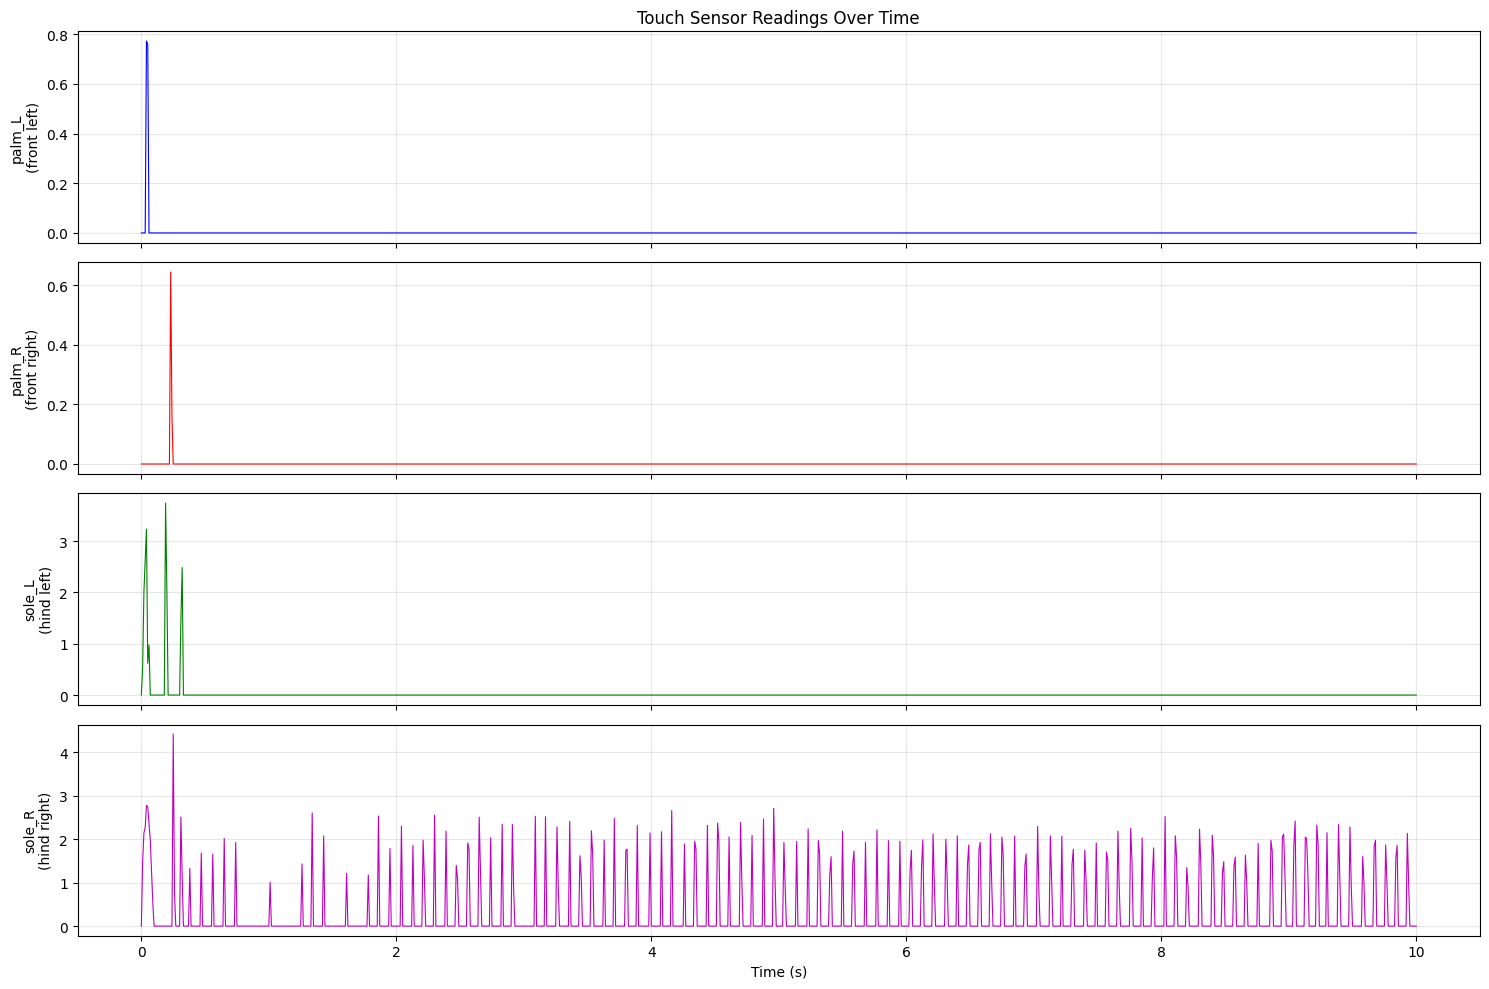

In [16]:
# Plot touch sensor data
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

timesteps = np.arange(num_timesteps)
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
time_sec = timesteps * ctrl_dt

# Palm L (front left / HL)
axes[0].plot(time_sec, palm_L_data_smooth, "b-", linewidth=0.8)
axes[0].set_ylabel("palm_L\n(front left)")
axes[0].set_title("Touch Sensor Readings Over Time")
axes[0].grid(True, alpha=0.3)

# Palm R (front right / HR)
axes[1].plot(time_sec, palm_R_data_smooth, "r-", linewidth=0.8)
axes[1].set_ylabel("palm_R\n(front right)")
axes[1].grid(True, alpha=0.3)

# Sole L (hind left / FL)
axes[2].plot(time_sec, sole_L_data_smooth, "g-", linewidth=0.8)
axes[2].set_ylabel("sole_L\n(hind left)")
axes[2].grid(True, alpha=0.3)

# Sole R (hind right / FR)
axes[3].plot(time_sec, sole_R_data_smooth, "m-", linewidth=0.8)
axes[3].set_ylabel("sole_R\n(hind right)")
axes[3].set_xlabel("Time (s)")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [17]:
# Binary stance detection from touch sensors (threshold-based)
TOUCH_THRESHOLD_PALM_L = 0.01
TOUCH_THRESHOLD_PALM_R = 0.01
TOUCH_THRESHOLD_SOLE_L = 0.01
TOUCH_THRESHOLD_SOLE_R = 0.01

if smooth:
    stance_palm_L = (palm_L_data_smooth > TOUCH_THRESHOLD_PALM_L).astype(int)
    stance_palm_R = (palm_R_data_smooth > TOUCH_THRESHOLD_PALM_R).astype(int)
    stance_sole_L = (sole_L_data_smooth > TOUCH_THRESHOLD_SOLE_L).astype(int)
    stance_sole_R = (sole_R_data_smooth > TOUCH_THRESHOLD_SOLE_R).astype(int)

else:
    stance_palm_L = (palm_L_data > TOUCH_THRESHOLD_PALM_L).astype(int)
    stance_palm_R = (palm_R_data > TOUCH_THRESHOLD_PALM_R).astype(int)
    stance_sole_L = (sole_L_data > TOUCH_THRESHOLD_SOLE_L).astype(int)
    stance_sole_R = (sole_R_data > TOUCH_THRESHOLD_SOLE_R).astype(int)

# Morphological closing: fill brief gaps (swing blips) in stance bouts
from scipy.ndimage import binary_closing, binary_opening

MIN_STANCE_GAP = 10  # close gaps up to this many timesteps
do_binary_closing = True

if do_binary_closing:
    structure = np.ones(MIN_STANCE_GAP)
    stance_palm_L = binary_closing(stance_palm_L, structure=structure).astype(int)
    stance_palm_R = binary_closing(stance_palm_R, structure=structure).astype(int)
    stance_sole_L = binary_closing(stance_sole_L, structure=structure).astype(int)
    stance_sole_R = binary_closing(stance_sole_R, structure=structure).astype(int)

# Morphological opening: remove brief stance bouts shorter than threshold
MIN_STANCE_DURATION = 6  # remove stance bouts shorter than this many timesteps
do_binary_opening = False

if do_binary_opening:
    structure = np.ones(MIN_STANCE_DURATION)
    stance_palm_L = binary_opening(stance_palm_L, structure=structure).astype(int)
    stance_palm_R = binary_opening(stance_palm_R, structure=structure).astype(int)
    stance_sole_L = binary_opening(stance_sole_L, structure=structure).astype(int)
    stance_sole_R = binary_opening(stance_sole_R, structure=structure).astype(int)

# Stack into barcode format [4, timesteps]
# Order: RH, RF, LF, LH (bottom to top in plot, so LH LF RF RH top to bottom)
# LH = Left Hind = sole_L, LF = Left Front = palm_L
# RF = Right Front = palm_R, RH = Right Hind = sole_R
contact_barcode = np.stack(
    [stance_sole_R, stance_palm_R, stance_palm_L, stance_sole_L], axis=0
)

print(f"Stance percentage per limb:")
limb_labels = ["RH (sole_R)", "RF (palm_R)", "LF (palm_L)", "LH (sole_L)"]
for i, label in enumerate(limb_labels):
    stance_pct = 100 * contact_barcode[i].sum() / num_timesteps
    print(f"  {label}: {stance_pct:.1f}%")

Stance percentage per limb:
  RH (sole_R): 87.5%
  RF (palm_R): 0.2%
  LF (palm_L): 0.1%
  LH (sole_L): 0.6%


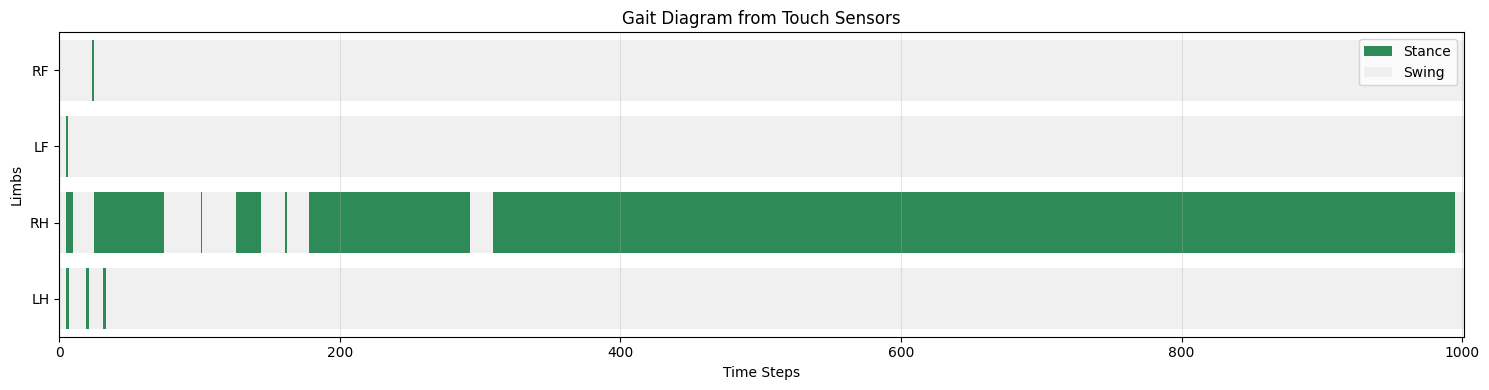

In [18]:
# Gait diagram plotting function
def plot_gait_diagram(
    contact_data,
    labels=None,
    title="Gait Diagram",
    figsize=(15, 4),
    stance_color="#2E8B57",
    swing_color="#F0F0F0",
):
    """Plot swing and stance phases for limbs over time."""
    if labels is None:
        labels = ["LH", "RH", "LF", "RF"]

    num_limbs, num_timesteps = contact_data.shape
    fig, ax = plt.subplots(figsize=figsize)

    for i, limb_label in enumerate(labels):
        # Find contiguous blocks to avoid anti-aliasing gaps between bars
        t = 0
        while t < num_timesteps:
            val = contact_data[i, t]
            color = stance_color if val == 1 else swing_color
            # Find the end of this contiguous block
            t_end = t + 1
            while t_end < num_timesteps and contact_data[i, t_end] == val:
                t_end += 1
            ax.barh(i, t_end - t, left=t, height=0.8, color=color, edgecolor="none")
            t = t_end

    ax.set_yticks(range(num_limbs))
    ax.set_yticklabels(labels)
    ax.set_xlabel("Time Steps")
    ax.set_ylabel("Limbs")
    ax.set_title(title)
    ax.set_xlim(0, num_timesteps)
    ax.set_ylim(-0.5, num_limbs - 0.5)
    ax.grid(True, alpha=0.3, axis="x")

    stance_patch = plt.Rectangle((0, 0), 1, 1, facecolor=stance_color)
    swing_patch = plt.Rectangle((0, 0), 1, 1, facecolor=swing_color)
    ax.legend([stance_patch, swing_patch], ["Stance", "Swing"], loc="upper right")

    plt.tight_layout()
    return fig, ax


# Plot gait diagram from touch sensor stance detection
# Reorder for display: RF > LF > RH > LH from top to bottom
plot_order = [3, 0, 2, 1]
fig, ax = plot_gait_diagram(
    contact_barcode[plot_order],
    labels=["LH", "RH", "LF", "RF"],
    title=f"Gait Diagram from Touch Sensors",
)
plt.show()

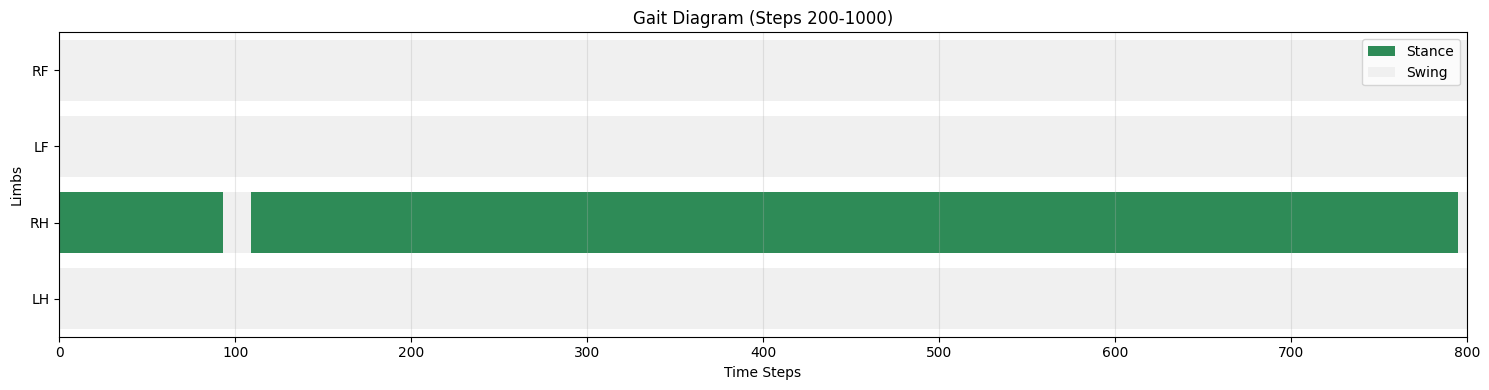

In [19]:
# Zoomed gait diagram
start_time = 200
end_time = 1000

# Reorder for display: RF > LF > RH > LH from top to bottom
plot_order = [3, 0, 2, 1]
fig, ax = plot_gait_diagram(
    contact_barcode[plot_order, start_time:end_time],
    labels=["LH", "RH", "LF", "RF"],
    title=f"Gait Diagram (Steps {start_time}-{end_time})",
)
plt.show()

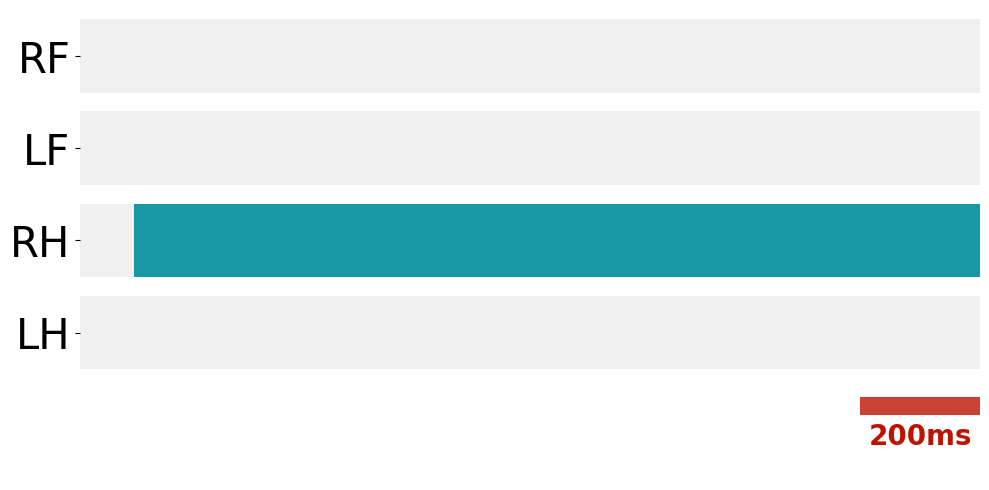

In [20]:
# Font size configuration
TICK_FONTSIZE = 30
XLABEL_FONTSIZE = 12
YLABEL_FONTSIZE = 12
TITLE_FONTSIZE = 30

# Color configuration (RGB 0-255)
STANCE_RGB = (24, 151, 165)
SCALE_BAR_RGB = (189, 19, 0)

stance_color = tuple(c / 255 for c in STANCE_RGB)
scale_bar_color = tuple(c / 255 for c in SCALE_BAR_RGB)

start_time = 300
end_time = 450
slice_len = end_time - start_time

# Display order: RF > LF > RH > LH from top to bottom
plot_order = [3, 0, 2, 1]
limb_names = ["LH", "RH", "LF", "RF"]

# Plot the 4-limb gait diagram
fig, ax = plot_gait_diagram(
    contact_barcode[plot_order, start_time:end_time],
    labels=limb_names,
    title=f"",
    figsize=(10, 5),
    stance_color=stance_color,
)
ax.get_legend().remove()

# Apply font sizes
ax.set_title(ax.get_title(), fontsize=TITLE_FONTSIZE)
ax.set_xlabel(ax.get_xlabel(), fontsize=XLABEL_FONTSIZE)
ax.set_ylabel(ax.get_ylabel(), fontsize=YLABEL_FONTSIZE)
ax.tick_params(axis="both", labelsize=TICK_FONTSIZE)

# Scale bar
SCALE_BAR_TIMESTEPS = 20  # 20 timesteps = 200 ms at ctrl_dt=0.01
SCALE_BAR_LABEL = "200ms"
scale_bar_y = -0.8
scale_bar_height = 0.2
scale_bar_start = slice_len - SCALE_BAR_TIMESTEPS

ax.barh(
    scale_bar_y,
    SCALE_BAR_TIMESTEPS,
    left=scale_bar_start,
    height=scale_bar_height,
    color=scale_bar_color,
    alpha=0.8,
    edgecolor="none",
)

ax.text(
    scale_bar_start + SCALE_BAR_TIMESTEPS / 2,
    scale_bar_y - scale_bar_height / 2 - 0.08,
    SCALE_BAR_LABEL,
    ha="center",
    va="top",
    color=scale_bar_color,
    fontsize=20,
    fontweight="bold",
)

# Expand ylim to fit the scale bar and label
ax.set_ylim(scale_bar_y - 0.8, len(limb_names) - 0.5)

ax.set_ylabel("")
ax.set_xlabel("")

ax.set_xticks([])
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

Analysis window: [0, 1000) timesteps
  RH: 7 complete bouts
  RF: 1 complete bout
  LF: 1 complete bout
  LH: 3 complete bouts


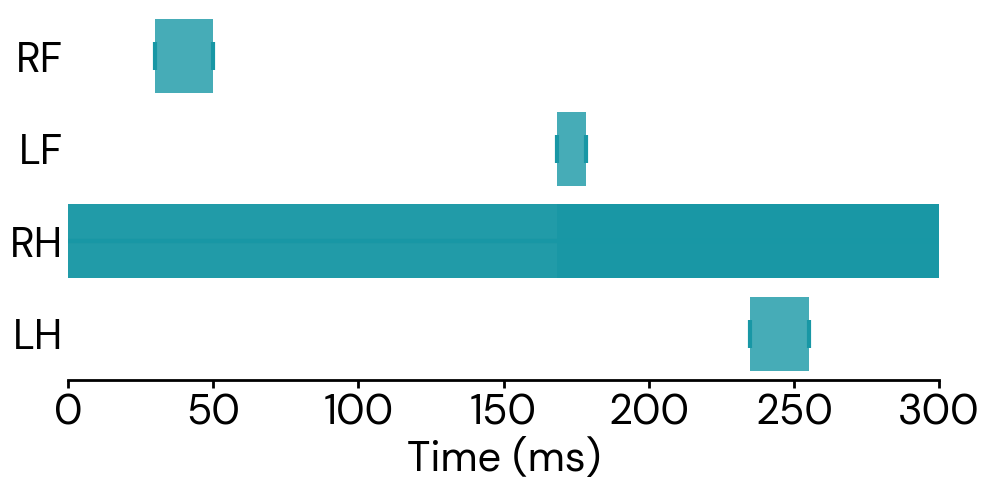

Mean stride period: 31.8 timesteps (318 ms)
RH: stance 1251 ± 2321 ms, phase offset 0 ms, n=7 bouts
RF: stance 20 ± 0 ms, phase offset 180 ms, n=1 bouts
LF: stance 10 ± 0 ms, phase offset 0 ms, n=1 bouts
LH: stance 20 ± 0 ms, phase offset 67 ms, n=3 bouts


In [21]:
import matplotlib

matplotlib.rcParams["font.family"] = "DM Sans"

# Compute mean stance duration and mean stride cycle phase per limb
limb_names = ["RH", "RF", "LF", "LH"]
stance_color = "#1897A5"
ctrl_dt_ms = 10  # each timestep = 10 ms
time_offset_ms = -150  # global time shift applied to the entire pattern (ms)
repeat_cycle = True  # repeat the mean gait pattern to fill the x-axis
xlim_ms = 300  # x-axis limit (ms)
alternate_limb_order = True  # False: LH>LF>RF>RH (top-bottom), True: RF>LF>RH>LH

# Analysis time window (in timesteps). Set to None to use full signal.
t_min = 0  # start timestep (inclusive), e.g. 50
t_max = 1000  # end timestep (exclusive), e.g. 500

# Display order (top to bottom on the plot)
if alternate_limb_order:
    display_order = ["LH", "RH", "LF", "RF"]
else:
    display_order = ["RH", "RF", "LF", "LH"]

# Extract stance bout start times, durations, and stride periods from contact_barcode
# Only includes complete bouts within the [t_min, t_max) window.
# Bouts cut off at either boundary (already in stance at t_min, or still in stance
# at t_max) are excluded since their true duration is unknown.
stance_durations = {}
stance_starts = {}
stride_periods = {}
for i, name in enumerate(limb_names):
    signal = contact_barcode[i]
    total_len = len(signal)

    # Resolve and clamp window bounds
    win_start = max(0, min(t_min if t_min is not None else 0, total_len))
    win_end = max(win_start, min(t_max if t_max is not None else total_len, total_len))

    windowed = signal[win_start:win_end]

    if len(windowed) == 0:
        stance_starts[name] = np.array([])
        stance_durations[name] = np.array([])
        stride_periods[name] = np.array([])
        continue

    starts = []
    durations = []
    in_stance = False
    bout_start = 0
    bout_len = 0
    # If the window starts mid-stance, the first bout is incomplete — flag for skip
    first_bout_cutoff = windowed[0] == 1
    is_first_bout = True

    for t, val in enumerate(windowed):
        if val == 1:
            if not in_stance:
                bout_start = win_start + t
                in_stance = True
                bout_len = 1
            else:
                bout_len += 1
        else:
            if in_stance:
                if is_first_bout and first_bout_cutoff:
                    # Skip: this bout started before the window
                    is_first_bout = False
                else:
                    starts.append(bout_start)
                    durations.append(bout_len)
                    is_first_bout = False
                bout_len = 0
                in_stance = False

    # If still in stance at end of window, this bout is cut off at t_max — skip it

    stance_starts[name] = np.array(starts)
    stance_durations[name] = np.array(durations)
    if len(starts) > 1:
        stride_periods[name] = np.diff(starts)
    else:
        stride_periods[name] = np.array([])

# Print window info
win_info = f"[{t_min if t_min is not None else 0}, {t_max if t_max is not None else contact_barcode.shape[1]})"
print(f"Analysis window: {win_info} timesteps")
for name in limb_names:
    n = len(stance_durations[name])
    print(f"  {name}: {n} complete bout{'s' if n != 1 else ''}")

# Compute stats, guarding against limbs with no complete bouts
valid_limbs = [name for name in limb_names if len(stance_durations[name]) > 0]
if len(valid_limbs) == 0:
    raise ValueError(
        "No complete stance bouts found in the analysis window. "
        "Try widening [t_min, t_max]."
    )

means = {name: stance_durations[name].mean() * ctrl_dt_ms for name in valid_limbs}
stds = {name: stance_durations[name].std() * ctrl_dt_ms for name in valid_limbs}

valid_stride_limbs = [name for name in limb_names if len(stride_periods[name]) > 0]
if len(valid_stride_limbs) > 0:
    mean_stride = np.mean([stride_periods[name].mean() for name in valid_stride_limbs])
else:
    raise ValueError(
        "Need ≥2 complete stance bouts on at least one limb to compute stride periods. "
        "Try widening [t_min, t_max]."
    )

# Compute mean phase offset relative to first limb within each stride cycle
ref_starts = stance_starts[limb_names[0]]
phase_offsets = {}
for name in limb_names:
    offsets = []
    if len(ref_starts) > 0:
        for s in stance_starts[name]:
            diffs = s - ref_starts
            valid = diffs[diffs >= 0]
            if len(valid) > 0:
                offsets.append(valid.min())
    phase_offsets[name] = np.mean(offsets) if len(offsets) > 0 else 0.0

# Convert to ms
cycle_len_ms = mean_stride * ctrl_dt_ms
phase_offsets_ms = {name: phase_offsets[name] * ctrl_dt_ms for name in limb_names}

# Compute repeat range to cover visible [0, xlim_ms] regardless of time_offset_ms
if repeat_cycle:
    r_start = int(np.floor(-time_offset_ms / cycle_len_ms)) - 1
    r_end = int(np.ceil((xlim_ms - time_offset_ms) / cycle_len_ms)) + 1
else:
    r_start = 0
    r_end = 1

# Plot: one stride cycle, each limb at its mean phase with mean stance duration
fig, ax = plt.subplots(figsize=(10, 5))

cap_half = 0.15  # half-height of the cap tick

for i, name in enumerate(display_order):
    if name not in means:
        # No complete bouts for this limb — skip drawing but keep y-position
        continue
    bar_start = phase_offsets_ms[name]
    mean_len = means[name]
    std_len = stds[name]

    for r in range(r_start, r_end):
        x0 = r * cycle_len_ms + time_offset_ms + bar_start
        ax.barh(
            i,
            mean_len,
            left=x0,
            height=0.8,
            color=stance_color,
            alpha=0.8,
            edgecolor="none",
        )

        # Right error bar
        right_end = x0 + mean_len + std_len
        ax.hlines(i, x0 + mean_len, right_end, colors=stance_color, linewidth=3)
        ax.vlines(
            right_end, i - cap_half, i + cap_half, colors=stance_color, linewidth=3
        )

        # Left error bar
        left_end = x0 - std_len
        ax.hlines(i, left_end, x0, colors=stance_color, linewidth=3)
        ax.vlines(
            left_end, i - cap_half, i + cap_half, colors=stance_color, linewidth=3
        )

ax.set_yticks(range(len(display_order)))
ax.set_yticklabels(display_order)
ax.set_xlim(0, xlim_ms)
ax.set_xlabel("Time (ms)", fontsize=TICK_FONTSIZE)
ax.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=2, length=6)
ax.tick_params(axis="y", labelsize=TICK_FONTSIZE, length=0)

ax.set_ylim(-0.5, len(display_order) - 0.5)
ax.set_ylabel("")
ax.grid(False)

ax.spines["bottom"].set_linewidth(2)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Print stats
print(f"Mean stride period: {mean_stride:.1f} timesteps ({cycle_len_ms:.0f} ms)")
for name in limb_names:
    d = stance_durations[name]
    if len(d) > 0:
        print(
            f"{name}: stance {d.mean() * ctrl_dt_ms:.0f} ± {d.std() * ctrl_dt_ms:.0f} ms, "
            f"phase offset {phase_offsets_ms[name]:.0f} ms, n={len(d)} bouts"
        )
    else:
        print(f"{name}: no complete bouts in window")

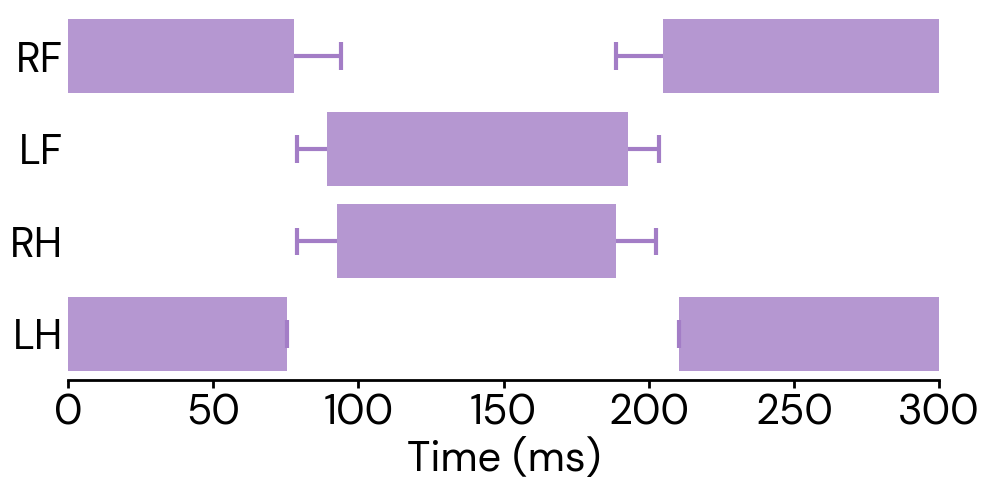

Rat walk_lat: n=359 strides, cycle=230 ms
  LH: phase=0.000±0.000, duty_factor=0.413, stance=95 ms
  RH: phase=0.488±0.060, duty_factor=0.416, stance=96 ms
  LF: phase=0.473±0.046, duty_factor=0.450, stance=104 ms
  RF: phase=0.975±0.070, duty_factor=0.448, stance=103 ms


In [22]:
# --- Real rat lateral-sequence walk gait diagram (from rat-sci-locomotion dataset) ---
from scipy.stats import circmean, circstd
import pandas as pd

df_phases_rat = pd.read_hdf(
    "/home/mila/a/aidan.sirbu/SCAMPER/data/df_phases.h5", key="df_phases"
)
df_wl = df_phases_rat[
    (df_phases_rat.SCI == "intact") & (df_phases_rat.gaits_all2 == "trot")
]
df_wl = df_wl[
    [
        "LR_h",
        "hl",
        "diag",
        "duty_factor_lh",
        "duty_factor_rh",
        "duty_factor_lf",
        "duty_factor_rf",
        "phase_dur",
    ]
].dropna()

# Compute stats (reference limb = LH at phase 0)
# Limb order: [lh, rh, lf, rf]
phases = [
    0.0,
    circmean(df_wl.LR_h, 1, 0),
    circmean(df_wl.hl, 1, 0),
    circmean(df_wl.diag, 1, 0),
]
phases_sd = [
    0.0,
    circstd(df_wl.LR_h, 1, 0),
    circstd(df_wl.hl, 1, 0),
    circstd(df_wl.diag, 1, 0),
]
duty_factors = [
    df_wl.duty_factor_lh.mean(),
    df_wl.duty_factor_rh.mean(),
    df_wl.duty_factor_lf.mean(),
    df_wl.duty_factor_rf.mean(),
]
cycle_len_ms = df_wl.phase_dur.mean() * 1000  # seconds -> ms

# Display order (top to bottom): LH, RH, LF, RF
rat_display_order = ["LH", "RH", "LF", "RF"]
rat_order_idx = [0, 1, 2, 3]  # indices into [lh, rh, lf, rf]

# Plotting parameters (match SCAMPER style)
rat_stance_color = "#A37DC6"
rat_time_offset_ms = -250
rat_xlim_ms = 300
rat_n_repeats = int(np.ceil((rat_xlim_ms - rat_time_offset_ms) / cycle_len_ms)) + 1

fig, ax = plt.subplots(figsize=(10, 5))
cap_half = 0.15

for i, name in enumerate(rat_display_order):
    idx = rat_order_idx[i]
    bar_start_ms = phases[idx] * cycle_len_ms
    mean_len_ms = duty_factors[idx] * cycle_len_ms
    std_len_ms = phases_sd[idx] * cycle_len_ms

    for r in range(rat_n_repeats):
        x0 = r * cycle_len_ms + rat_time_offset_ms + bar_start_ms
        ax.barh(
            i,
            mean_len_ms,
            left=x0,
            height=0.8,
            color=rat_stance_color,
            alpha=0.8,
            edgecolor="none",
        )

        # Right error bar (stance duration variability via phase std as proxy)
        right_end = x0 + mean_len_ms + std_len_ms
        ax.hlines(i, x0 + mean_len_ms, right_end, colors=rat_stance_color, linewidth=3)
        ax.vlines(
            right_end, i - cap_half, i + cap_half, colors=rat_stance_color, linewidth=3
        )

        # Left error bar
        left_end = x0 - std_len_ms
        ax.hlines(i, left_end, x0, colors=rat_stance_color, linewidth=3)
        ax.vlines(
            left_end, i - cap_half, i + cap_half, colors=rat_stance_color, linewidth=3
        )

ax.set_yticks(range(len(rat_display_order)))
ax.set_yticklabels(rat_display_order)
ax.set_xlim(0, rat_xlim_ms)
ax.set_xlabel("Time (ms)", fontsize=TICK_FONTSIZE)
ax.tick_params(axis="x", labelsize=TICK_FONTSIZE, width=2, length=6)
ax.tick_params(axis="y", labelsize=TICK_FONTSIZE, length=0)
ax.set_ylim(-0.5, len(rat_display_order) - 0.5)
ax.set_ylabel("")
ax.grid(False)

ax.spines["bottom"].set_linewidth(2)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Print stats
print(f"Rat walk_lat: n={len(df_wl)} strides, cycle={cycle_len_ms:.0f} ms")
for i, name in enumerate(["lh", "rh", "lf", "rf"]):
    print(
        f"  {name.upper()}: phase={phases[i]:.3f}±{phases_sd[i]:.3f}, "
        f"duty_factor={duty_factors[i]:.3f}, "
        f"stance={duty_factors[i] * cycle_len_ms:.0f} ms"
    )

In [23]:
# --- Compare gait metrics: SCAMPER rollout vs Real rat lateral-sequence walk ---
import pandas as pd
from scipy.stats import circstd as _circstd

limb_order = ["LH", "RH", "LF", "RF"]

# ===== SCAMPER rollout metrics (from contact_barcode analysis) =====
scamper_cycle_ms = (
    mean_stride * ctrl_dt_ms
)  # recompute (cycle_len_ms overwritten by rat cell)

# Limbs with no complete stance bouts (e.g. a crawling scratch policy whose
# RF/LF never make contact) are absent from `means`/`stds`. Fill with NaN so
# the comparison table flags them instead of crashing.
NAN = float("nan")
scamper_stance_ms = {name: means.get(name, NAN) for name in limb_order}
scamper_stance_std_ms = {name: stds.get(name, NAN) for name in limb_order}
scamper_n_bouts = {name: len(stance_durations[name]) for name in limb_order}

# Per-bout swing duration: pair each stance bout with its stride period
scamper_swing_ms = {}
scamper_swing_std_ms = {}
for name in limb_order:
    n_strides = len(stride_periods[name])
    n_stance = len(stance_durations[name])
    if n_strides > 0 and n_stance > 0:
        n_pair = min(n_strides, n_stance)
        swing_ts = stride_periods[name][:n_pair] - stance_durations[name][:n_pair]
        scamper_swing_ms[name] = swing_ts.mean() * ctrl_dt_ms
        scamper_swing_std_ms[name] = swing_ts.std() * ctrl_dt_ms
    elif n_stance > 0:
        scamper_swing_ms[name] = scamper_cycle_ms - means[name]
        scamper_swing_std_ms[name] = 0.0
    else:
        scamper_swing_ms[name] = NAN
        scamper_swing_std_ms[name] = NAN

scamper_duty = {
    name: (means[name] / scamper_cycle_ms) if name in means else NAN
    for name in limb_order
}
scamper_duty_std = {
    name: (stds[name] / scamper_cycle_ms) if name in stds else NAN
    for name in limb_order
}

# Per-stride step frequency (only from limbs that produced strides)
nonempty_stride_arrays = [
    stride_periods[name] for name in limb_names if len(stride_periods[name]) > 0
]
if nonempty_stride_arrays:
    all_stride_periods_ts = np.concatenate(nonempty_stride_arrays)
    scamper_stride_std_ms = all_stride_periods_ts.std() * ctrl_dt_ms
    scamper_step_freqs = 1000 / (all_stride_periods_ts * ctrl_dt_ms)
    scamper_step_freq = scamper_step_freqs.mean()
    scamper_step_freq_std = scamper_step_freqs.std()
else:
    scamper_stride_std_ms = NAN
    scamper_step_freq = NAN
    scamper_step_freq_std = NAN

# Per-stride temporal symmetry (needs both LH and RH bouts/strides)
scamper_temp_sym_per_stride = []
n_lh = min(len(stride_periods["LH"]), len(stance_durations["LH"]))
n_rh = min(len(stride_periods["RH"]), len(stance_durations["RH"]))
for i in range(min(n_lh, n_rh)):
    lh_duty = stance_durations["LH"][i] / stride_periods["LH"][i]
    rh_duty = stance_durations["RH"][i] / stride_periods["RH"][i]
    scamper_temp_sym_per_stride.append((lh_duty - rh_duty) / (lh_duty + rh_duty))
scamper_temp_sym_per_stride = np.array(scamper_temp_sym_per_stride)
if scamper_temp_sym_per_stride.size > 0:
    scamper_temp_sym = scamper_temp_sym_per_stride.mean()
    scamper_temp_sym_std = scamper_temp_sym_per_stride.std()
else:
    scamper_temp_sym = NAN
    scamper_temp_sym_std = NAN

# Phase offsets relative to LH (to match rat reference limb convention)
scamper_phases_rel_lh = {}
scamper_phases_rel_lh_std = {}
lh_starts = stance_starts["LH"]
for name in limb_order:
    if len(lh_starts) == 0 or len(stance_starts[name]) == 0:
        scamper_phases_rel_lh[name] = NAN
        scamper_phases_rel_lh_std[name] = NAN
        continue
    per_bout = []
    for s in stance_starts[name]:
        diffs = s - lh_starts
        valid = diffs[diffs >= 0]
        if len(valid) > 0:
            per_bout.append(valid.min())
    per_bout = np.array(per_bout)
    if per_bout.size > 0:
        phase_frac = (per_bout % mean_stride) / mean_stride
        scamper_phases_rel_lh[name] = phase_frac.mean()
        scamper_phases_rel_lh_std[name] = phase_frac.std()
    else:
        scamper_phases_rel_lh[name] = NAN
        scamper_phases_rel_lh_std[name] = NAN

# ===== Real rat metrics (from df_wl) =====
rat_cycle_ms = cycle_len_ms  # now the rat value
rat_stride_std_ms = df_wl.phase_dur.std() * 1000

rat_stance_ms_per_stride = {
    "LH": df_wl.duty_factor_lh * df_wl.phase_dur * 1000,
    "RH": df_wl.duty_factor_rh * df_wl.phase_dur * 1000,
    "LF": df_wl.duty_factor_lf * df_wl.phase_dur * 1000,
    "RF": df_wl.duty_factor_rf * df_wl.phase_dur * 1000,
}
rat_stance_ms = {name: rat_stance_ms_per_stride[name].mean() for name in limb_order}
rat_stance_std_ms = {name: rat_stance_ms_per_stride[name].std() for name in limb_order}

rat_swing_ms_per_stride = {
    name: df_wl.phase_dur * 1000 - rat_stance_ms_per_stride[name] for name in limb_order
}
rat_swing_ms = {name: rat_swing_ms_per_stride[name].mean() for name in limb_order}
rat_swing_std_ms = {name: rat_swing_ms_per_stride[name].std() for name in limb_order}

rat_duty = {
    name.upper(): duty_factors[i] for i, name in enumerate(["lh", "rh", "lf", "rf"])
}
rat_duty_std = {
    "LH": df_wl.duty_factor_lh.std(),
    "RH": df_wl.duty_factor_rh.std(),
    "LF": df_wl.duty_factor_lf.std(),
    "RF": df_wl.duty_factor_rf.std(),
}

rat_step_freqs = 1000 / (df_wl.phase_dur * 1000)
rat_step_freq = rat_step_freqs.mean()
rat_step_freq_std = rat_step_freqs.std()

rat_temp_sym_per_stride = (df_wl.duty_factor_lh - df_wl.duty_factor_rh) / (
    df_wl.duty_factor_lh + df_wl.duty_factor_rh
)
rat_temp_sym = rat_temp_sym_per_stride.mean()
rat_temp_sym_std = rat_temp_sym_per_stride.std()

rat_hindlimb_lag = phases[1]
rat_homolateral = phases[2]
rat_diagonal = phases[3]

# ===== Build comparison table with sigma distance =====
# rows: (metric, table1_#, scamper_mean, scamper_std, rat_mean, rat_std, fmt)
# fmt: number of decimal places for mean and std formatting
raw_rows = []

raw_rows.append(
    (
        "Stride Duration (ms)",
        4,
        scamper_cycle_ms,
        scamper_stride_std_ms,
        rat_cycle_ms,
        rat_stride_std_ms,
        0,
    )
)
raw_rows.append(
    (
        "Step Frequency (Hz)",
        15,
        scamper_step_freq,
        scamper_step_freq_std,
        rat_step_freq,
        rat_step_freq_std,
        2,
    )
)

for name in limb_order:
    raw_rows.append(
        (
            f"Stance Duration {name} (ms)",
            17,
            scamper_stance_ms[name],
            scamper_stance_std_ms[name],
            rat_stance_ms[name],
            rat_stance_std_ms[name],
            0,
        )
    )

for name in limb_order:
    raw_rows.append(
        (
            f"Swing Duration {name} (ms)",
            18,
            scamper_swing_ms[name],
            scamper_swing_std_ms[name],
            rat_swing_ms[name],
            rat_swing_std_ms[name],
            0,
        )
    )

for name in limb_order:
    raw_rows.append(
        (
            f"Duty Factor {name}",
            6,
            scamper_duty[name],
            scamper_duty_std[name],
            rat_duty[name],
            rat_duty_std[name],
            3,
        )
    )

raw_rows.append(
    (
        "Temporal Symmetry (hind)",
        7,
        scamper_temp_sym,
        scamper_temp_sym_std,
        rat_temp_sym,
        rat_temp_sym_std,
        4,
    )
)

raw_rows.append(
    (
        "Hindlimb Phase Lag (RH rel. LH)",
        16,
        scamper_phases_rel_lh["RH"],
        scamper_phases_rel_lh_std["RH"],
        rat_hindlimb_lag,
        phases_sd[1],
        3,
    )
)
raw_rows.append(
    (
        "Homolateral Coupling (LF rel. LH)",
        20,
        scamper_phases_rel_lh["LF"],
        scamper_phases_rel_lh_std["LF"],
        rat_homolateral,
        phases_sd[2],
        3,
    )
)
raw_rows.append(
    (
        "Diagonal Coupling (RF rel. LH)",
        19,
        scamper_phases_rel_lh["RF"],
        scamper_phases_rel_lh_std["RF"],
        rat_diagonal,
        phases_sd[3],
        3,
    )
)


# Format and compute sigma distance + Gaussian similarity
# Δσ uses r_std (rat variability) so models are compared on the same scale
coordination_metric_names = {
    "Temporal Symmetry (hind)",
    "Hindlimb Phase Lag (RH rel. LH)",
    "Homolateral Coupling (LF rel. LH)",
    "Diagonal Coupling (RF rel. LH)",
}


def _isnan(v):
    return isinstance(v, float) and np.isnan(v)


def _fmt(v, dp):
    return "—" if (v is None or _isnan(v)) else f"{v:.{dp}f}"


table_rows = []
coord_sigma_list = []
all_sigma_list = []
missing_metrics = []
for metric, tnum, s_mean, s_std, r_mean, r_std, dp in raw_rows:
    s_str = f"{_fmt(s_mean, dp)} ± {_fmt(s_std, dp)}"
    r_str = f"{_fmt(r_mean, dp)} ± {_fmt(r_std, dp)}"
    if _isnan(s_mean):
        sigma_str = "—"
        sim_str = "—"
        missing_metrics.append(metric)
    elif r_std is None or r_std == 0 or _isnan(r_std):
        sigma_str = "inf"
        sim_str = "0.000"
    else:
        sigma_dist = abs(s_mean - r_mean) / r_std
        similarity = np.exp(-0.5 * sigma_dist**2)
        sigma_str = f"{sigma_dist:.2f}"
        sim_str = f"{similarity:.3f}"
        if metric in coordination_metric_names:
            coord_sigma_list.append(sigma_dist)
        all_sigma_list.append(sigma_dist)
    table_rows.append((metric, tnum, s_str, r_str, sigma_str, sim_str))

# Overall summary rows (excluding metrics that couldn't be computed)
coord_sigmas = np.array(coord_sigma_list)
all_sigmas = np.array(all_sigma_list)
overall_all = (
    (f"{all_sigmas.mean():.2f}", f"{np.exp(-0.5 * all_sigmas**2).mean():.3f}")
    if all_sigmas.size > 0
    else ("—", "—")
)
overall_coord = (
    (f"{coord_sigmas.mean():.2f}", f"{np.exp(-0.5 * coord_sigmas**2).mean():.3f}")
    if coord_sigmas.size > 0
    else ("—", "—")
)
table_rows.append(("Overall (all metrics)", "", "", "", *overall_all))
table_rows.append(("Overall (coordination)", "", "", "", *overall_coord))

comparison_df = pd.DataFrame(
    table_rows,
    columns=[
        "Metric",
        "Table 1 #",
        "SCAMPER Rollout",
        "Real Rat (walk_lat)",
        "Δσ",
        "Similarity",
    ],
)

print(
    f"SCAMPER: {sum(scamper_n_bouts.values())} total stance bouts "
    f"({', '.join(f'{k}={v}' for k, v in scamper_n_bouts.items())})"
)
if missing_metrics:
    print(
        f"NOTE: {len(missing_metrics)} metric(s) unavailable (limb never made contact "
        "or insufficient bouts) — shown as '—' and excluded from Overall."
    )
print(f"Real rat: n={len(df_wl)} strides")
print(f"\nΔσ = |mean_rollout - mean_rat| / σ_rat")
print(f"Similarity = exp(-0.5 * Δσ²)  (1.0 = perfect match)")
print(f"Overall = mean similarity across metrics\n")
print(comparison_df.to_string(index=False))
comparison_df

SCAMPER: 12 total stance bouts (LH=3, RH=7, LF=1, RF=1)
Real rat: n=359 strides

Δσ = |mean_rollout - mean_rat| / σ_rat
Similarity = exp(-0.5 * Δσ²)  (1.0 = perfect match)
Overall = mean similarity across metrics

                           Metric Table 1 #  SCAMPER Rollout Real Rat (walk_lat)    Δσ Similarity
             Stride Duration (ms)         4        318 ± 391            230 ± 31  2.84      0.018
              Step Frequency (Hz)        15      4.41 ± 2.52         4.42 ± 0.56  0.01      1.000
          Stance Duration LH (ms)        17           20 ± 0             97 ± 27  2.88      0.016
          Stance Duration RH (ms)        17      1251 ± 2321             97 ± 25 46.48      0.000
          Stance Duration LF (ms)        17           10 ± 0            104 ± 23  4.16      0.000
          Stance Duration RF (ms)        17           20 ± 0            104 ± 24  3.56      0.002
           Swing Duration LH (ms)        18         110 ± 10            134 ± 14  1.72      0.227
  

,Metric,Table 1 #,SCAMPER Rollout,Real Rat (walk_lat),Δσ,Similarity
0,Stride Duration (ms),4,318 ± 391,230 ± 31,2.84,0.018
1,Step Frequency (Hz),15,4.41 ± 2.52,4.42 ± 0.56,0.01,1.000
2,Stance Duration LH (ms),17,20 ± 0,97 ± 27,2.88,0.016
3,Stance Duration RH (ms),17,1251 ± 2321,97 ± 25,46.48,0.000
4,Stance Duration LF (ms),17,10 ± 0,104 ± 23,4.16,0.000
5,Stance Duration RF (ms),17,20 ± 0,104 ± 24,3.56,0.002
6,Swing Duration LH (ms),18,110 ± 10,134 ± 14,1.72,0.227
7,Swing Duration RH (ms),18,190 ± 43,133 ± 15,3.88,0.001
8,Swing Duration LF (ms),18,308 ± 0,126 ± 16,11.69,0.000
9,Swing Duration RF (ms),18,298 ± 0,126 ± 16,10.62,0.000


In [24]:
# Summary statistics
print("=" * 60)
print("Touch Sensor Gait Analysis Summary")
print("=" * 60)
print(f"\nCheckpoint: {CHECKPOINT_PATH}")
print(f"Step: {ckpt_step}")
print(f"Target speed: {env_cfg.target_speed} m/s")
print(f"Episode length: {num_timesteps} steps ({num_timesteps * ctrl_dt:.1f} s)")

print("\nStance percentages:")
limb_labels = ["RH (sole_R)", "RF (palm_R)", "LF (palm_L)", "LH (sole_L)"]
for i, label in enumerate(limb_labels):
    stance_pct = 100 * contact_barcode[i].sum() / num_timesteps
    print(f"  {label}: {stance_pct:.1f}%")

print("\nTouch sensor force statistics:")
print(f"  palm_L: mean={palm_L_data.mean():.4f}, max={palm_L_data.max():.4f}")
print(f"  palm_R: mean={palm_R_data.mean():.4f}, max={palm_R_data.max():.4f}")
print(f"  sole_L: mean={sole_L_data.mean():.4f}, max={sole_L_data.max():.4f}")
print(f"  sole_R: mean={sole_R_data.mean():.4f}, max={sole_R_data.max():.4f}")

Touch Sensor Gait Analysis Summary

Checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_velocity_checkpoints/260228_120949_207733
Step: 25
Target speed: 0.5 m/s
Episode length: 1001 steps (10.0 s)

Stance percentages:
  RH (sole_R): 87.5%
  RF (palm_R): 0.2%
  LF (palm_L): 0.1%
  LH (sole_L): 0.6%

Touch sensor force statistics:
  palm_L: mean=0.0015, max=0.7729
  palm_R: mean=0.0008, max=0.6449
  sole_L: mean=0.0197, max=3.7402
  sole_R: mean=0.3040, max=4.4192


## Gait Cycle Detection and Metrics

Detect individual gait cycles and compute biomechanical metrics.

In [31]:
def find_gait_cycles(
    contact_barcode,
    limb_index=1,
    start_time=0,
    end_time=None,
    min_cycle_length=20,
):
    """
    Find gait cycles based on stance phase onsets.

    Args:
        contact_barcode: Shape [4, timesteps] contact data
        limb_index: Which limb to use for detection (0=RH, 1=RF, 2=LF, 3=LH)
        start_time: Start of analysis window
        end_time: End of analysis window (None = end of data)
        smooth: Whether to apply median filtering
        smooth_kernel_size: Kernel size for median filter (smaller = preserve more detail)
        smooth_limbs: List of limb indices to smooth. None = all limbs.
            Only applies smoothing to limb_index if it is in this list.
        min_cycle_length: Minimum valid cycle length in timesteps

    Returns:
        List of (cycle_start, cycle_end) tuples
    """
    if end_time is None:
        end_time = contact_barcode.shape[1]

    contacts = contact_barcode[limb_index, start_time:end_time]

    # Find stance onsets (transitions from 0 to 1)
    stance_onsets = []
    for i in range(1, len(contacts)):
        if contacts[i - 1] == 0 and contacts[i] == 1:
            stance_onsets.append(start_time + i)

    # Filter out onsets that are too close together
    filtered_onsets = []
    if len(stance_onsets) > 0:
        filtered_onsets.append(stance_onsets[0])
        for onset in stance_onsets[1:]:
            if onset - filtered_onsets[-1] >= min_cycle_length:
                filtered_onsets.append(onset)

    # Create gait cycles from consecutive stance onsets
    gait_cycles = []
    for i in range(len(filtered_onsets) - 1):
        cycle_start = filtered_onsets[i]
        cycle_end = filtered_onsets[i + 1]
        if cycle_end - cycle_start >= min_cycle_length:
            gait_cycles.append((cycle_start, cycle_end))

    return gait_cycles

In [32]:
# Mapping from limb_index to foot body index (for xpos extraction)
# Updated to match new barcode order: [RH, RF, LF, LH]
limb_to_body_mapping = {
    0: 17,  # RH (Right Hind = sole_R) -> foot_R body
    1: 66,  # RF (Right Front = palm_R) -> hand_R body
    2: 61,  # LF (Left Front = palm_L) -> hand_L body
    3: 13,  # LH (Left Hind = sole_L) -> foot_L body
}


def compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=1,
    ctrl_dt=0.02,
):
    """
    Compute gait metrics for each gait cycle.

    Args:
        smooth_limbs: List of limb indices to smooth. None = all limbs.
            Only applies smoothing to limb_index if it is in this list.

    Returns dict with:
    - stride_length_mm: List of stride lengths in mm
    - velocity_cm_per_sec: List of velocities in cm/s
    - cadence_steps_per_min: List of cadences in steps/min (true cadence = 2x stride freq)
    - stance_percentage: List of stance percentages
    - cycle_lengths: List of cycle lengths in timesteps
    """
    foot_body_idx = limb_to_body_mapping.get(limb_index)

    metrics = {
        "stride_length_mm": [],
        "velocity_cm_per_sec": [],
        "cadence_steps_per_min": [],
        "stance_percentage": [],
        "cycle_lengths": [],
    }

    smooth_contacts = contact_barcode[limb_index, :]

    for cycle_start, cycle_end in gait_cycles:
        cycle_length = cycle_end - cycle_start
        metrics["cycle_lengths"].append(cycle_length)

        # 1. Stride Length (mm)
        if foot_body_idx is not None:
            foot_pos_start = np.array(rollout[cycle_start].data.xpos[foot_body_idx])
            foot_pos_end = np.array(rollout[cycle_end].data.xpos[foot_body_idx])
            stride_length_m = np.linalg.norm(foot_pos_end - foot_pos_start)
            stride_length_mm = stride_length_m * 1000.0
            metrics["stride_length_mm"].append(stride_length_mm)

            # 2. Velocity (cm/sec)
            cycle_duration_sec = cycle_length * ctrl_dt
            velocity_m_per_sec = stride_length_m / cycle_duration_sec
            velocity_cm_per_sec = velocity_m_per_sec * 100.0
            metrics["velocity_cm_per_sec"].append(velocity_cm_per_sec)

            # 3. Cadence (steps/min)
            # Each stride cycle = 2 steps (one per limb pair: L + R)
            stride_freq = 1.0 / cycle_duration_sec
            cadence_steps_per_min = stride_freq * 2.0 * 60.0
            metrics["cadence_steps_per_min"].append(cadence_steps_per_min)

        # 4. Stance Percentage
        cycle_contacts = smooth_contacts[cycle_start:cycle_end]
        stance_pct = 100.0 * np.sum(cycle_contacts) / len(cycle_contacts)
        metrics["stance_percentage"].append(stance_pct)

    return metrics

In [33]:
# Find gait cycles using RF (Right Front) limb
# New barcode order: 0=RH, 1=RF, 2=LF, 3=LH
gait_detection_limb = 0
analysis_start = 50  # Skip initial transient
analysis_end = 1000  # Skip final steps

gait_cycles = find_gait_cycles(
    contact_barcode,
    limb_index=gait_detection_limb,
    start_time=analysis_start,
    end_time=analysis_end,
    min_cycle_length=20,
)

print(f"Found {len(gait_cycles)} gait cycles")
for i, (start, end) in enumerate(gait_cycles[:5]):
    print(f"  Cycle {i+1}: steps {start}-{end} (length: {end-start})")
if len(gait_cycles) > 5:
    print(f"  ... and {len(gait_cycles) - 5} more cycles")

Found 27 gait cycles
  Cycle 1: steps 66-99 (length: 33)
  Cycle 2: steps 99-131 (length: 32)
  Cycle 3: steps 131-163 (length: 32)
  Cycle 4: steps 163-195 (length: 32)
  Cycle 5: steps 195-227 (length: 32)
  ... and 22 more cycles


In [34]:
# Compute gait metrics
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]

gait_metrics = compute_gait_metrics(
    rollout,
    contact_barcode,
    gait_cycles,
    limb_index=gait_detection_limb,
    ctrl_dt=ctrl_dt,
)

print("\nGait Metrics Summary:")
print("-" * 50)

if gait_metrics["stride_length_mm"]:
    print(
        f"Stride Length: {np.mean(gait_metrics['stride_length_mm']):.1f} +/- {np.std(gait_metrics['stride_length_mm']):.1f} mm"
    )
    print(
        f"Velocity: {np.mean(gait_metrics['velocity_cm_per_sec']):.1f} +/- {np.std(gait_metrics['velocity_cm_per_sec']):.1f} cm/s"
    )
    print(
        f"Cadence: {np.mean(gait_metrics['cadence_steps_per_min']):.1f} +/- {np.std(gait_metrics['cadence_steps_per_min']):.1f} steps/min"
    )

if gait_metrics["stance_percentage"]:
    print(
        f"Stance Percentage: {np.mean(gait_metrics['stance_percentage']):.1f} +/- {np.std(gait_metrics['stance_percentage']):.1f} %"
    )
    print(
        f"Cycle Length: {np.mean(gait_metrics['cycle_lengths']):.1f} +/- {np.std(gait_metrics['cycle_lengths']):.1f} timesteps"
    )
else:
    print("No gait cycles detected - try adjusting threshold or smoothing parameters")


Gait Metrics Summary:
--------------------------------------------------
Stride Length: 99.7 +/- 2.0 mm
Velocity: 30.0 +/- 0.2 cm/s
Cadence: 361.0 +/- 7.7 steps/min
Stance Percentage: 55.2 +/- 1.3 %
Cycle Length: 33.3 +/- 0.7 timesteps


## Summary Statistics Table

In [35]:
# Create summary table
import pandas as pd

summary_data = {
    "Metric": [],
    "Mean": [],
    "Std": [],
    "Min": [],
    "Max": [],
    "N": [],
}

metrics_info = [
    ("Stride Length (mm)", gait_metrics["stride_length_mm"]),
    ("Velocity (cm/s)", gait_metrics["velocity_cm_per_sec"]),
    ("Cadence (steps/min)", gait_metrics["cadence_steps_per_min"]),
    ("Stance Percentage (%)", gait_metrics["stance_percentage"]),
    ("Cycle Length (timesteps)", gait_metrics["cycle_lengths"]),
]

for name, values in metrics_info:
    if values:
        summary_data["Metric"].append(name)
        summary_data["Mean"].append(f"{np.mean(values):.2f}")
        summary_data["Std"].append(f"{np.std(values):.2f}")
        summary_data["Min"].append(f"{np.min(values):.2f}")
        summary_data["Max"].append(f"{np.max(values):.2f}")
        summary_data["N"].append(len(values))

summary_df = pd.DataFrame(summary_data)
print("\nGait Metrics Summary")
print("=" * 80)
print(summary_df.to_string(index=False))

# Save to CSV
summary_df.to_csv(OUTPUT_DIR / "gait_metrics_summary.csv", index=False)
print(f"\nSummary saved to: {OUTPUT_DIR / 'gait_metrics_summary.csv'}")


Gait Metrics Summary
                  Metric   Mean  Std    Min    Max  N
      Stride Length (mm)  99.66 2.04  95.53 102.40 27
         Velocity (cm/s)  29.97 0.18  29.65  30.34 27
     Cadence (steps/min) 360.96 7.65 352.94 375.00 27
   Stance Percentage (%)  55.22 1.29  51.52  57.58 27
Cycle Length (timesteps)  33.26 0.70  32.00  34.00 27

Summary saved to: /home/mila/a/aidan.sirbu/SCAMPER/data/final_maintain_velocity_analysis/SCAMPER_S3e-1/gait_metrics_summary.csv


In [36]:
# Display as styled table
summary_df

,Metric,Mean,Std,Min,Max,N
0,Stride Length (mm),99.66,2.04,95.53,102.40,27
1,Velocity (cm/s),29.97,0.18,29.65,30.34,27
2,Cadence (steps/min),360.96,7.65,352.94,375.00,27
3,Stance Percentage (%),55.22,1.29,51.52,57.58,27
4,Cycle Length (timesteps),33.26,0.70,32.00,34.00,27


## Average Gait Cycle Joint Angle Profiles

Normalize each gait cycle to 0-100% and compute mean +/- std of joint angles across cycles.

In [37]:
from scipy import interpolate


def normalize_to_gait_percentage(data, cycle_length):
    """Interpolate variable-length cycle data to a standard 100-point gait percentage."""
    original_time = np.linspace(0, 100, cycle_length)
    target_time = np.linspace(0, 100, 100)
    try:
        interp_func = interpolate.interp1d(
            original_time,
            data,
            kind="cubic",
            bounds_error=False,
            fill_value="extrapolate",
        )
        return interp_func(target_time)
    except ValueError:
        interp_func = interpolate.interp1d(
            original_time,
            data,
            kind="linear",
            bounds_error=False,
            fill_value="extrapolate",
        )
        return interp_func(target_time)


# === Configuration: qpos indices and labels to analyze ===
# Forelimbs: Shoulder-L(61), Shoulder-R(69), Elbow-L(63), Elbow-R(71)
# Hindlimbs: Hip-L(15), Hip-R(21), Knee-L(16), Knee-R(22)
QPOS_INDICES = [15, 21, 16, 22, 17, 23, 61, 69, 63, 71]
QPOS_LABELS = {
    15: "Hip-L",
    21: "Hip-R",
    16: "Knee-L",
    22: "Knee-R",
    17: "Ankle-L",
    23: "Ankle-R",
    61: "Shoulder-L",
    69: "Shoulder-R",
    63: "Elbow-L",
    71: "Elbow-R",
}
CONVERT_TO_DEGREES = True

# === Phase offsets per qpos index (0-100%, circular shift of the gait cycle) ===
# e.g. 50 means the cycle is shifted by half a period.
# Joints not listed default to 0 (no shift).
PHASE_OFFSETS = {
    # 16: 10,
    # 15: 10,
    # 21: 50,  # Hip-R: shift 50% to align with Hip-L
    # 22: 50,  # Knee-R
    # 23: 50,  # Ankle-R
    # 69: 50,  # Shoulder-R
    # 71: 50,  # Elbow-R
}

# Extract qpos timeseries from rollout (shape: [timesteps, n_qpos])
qpos_all = np.array([np.array(state.data.qpos) for state in rollout])
print(f"Extracted qpos: shape {qpos_all.shape}")

# Collect normalised cycles for every joint
joint_cycle_data = {idx: [] for idx in QPOS_INDICES}

for cycle_start, cycle_end in gait_cycles:
    cycle_length = cycle_end - cycle_start
    for qpos_idx in QPOS_INDICES:
        segment = qpos_all[cycle_start:cycle_end, qpos_idx]
        normalised = normalize_to_gait_percentage(segment, cycle_length)
        # Apply phase offset (circular roll on the 100-point array)
        shift = PHASE_OFFSETS.get(qpos_idx, 0)
        if shift != 0:
            normalised = np.roll(normalised, int(round(shift)))
        joint_cycle_data[qpos_idx].append(normalised)

# Compute mean and std across cycles
joint_cycle_stats = {}
for qpos_idx in QPOS_INDICES:
    cycles_arr = np.array(joint_cycle_data[qpos_idx])  # (n_cycles, 100)
    if CONVERT_TO_DEGREES:
        cycles_arr = np.degrees(cycles_arr)
    joint_cycle_stats[qpos_idx] = {
        "mean": np.mean(cycles_arr, axis=0),
        "std": np.std(cycles_arr, axis=0),
        "n_cycles": len(joint_cycle_data[qpos_idx]),
        "raw_cycles": cycles_arr,
    }

n_cycles = joint_cycle_stats[QPOS_INDICES[0]]["n_cycles"]
print(f"Averaged {n_cycles} gait cycles across {len(QPOS_INDICES)} joints")
if any(v != 0 for v in PHASE_OFFSETS.values()):
    print(
        f"Phase offsets applied: { {QPOS_LABELS.get(k, k): v for k, v in PHASE_OFFSETS.items() if v != 0} }"
    )

Extracted qpos: shape (1001, 74)
Averaged 27 gait cycles across 10 joints


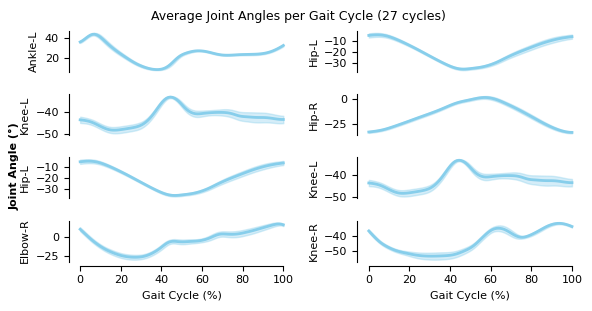

In [ ]:
# Plot average gait cycle joint angle profiles (2-column: forelimbs | hindlimbs)
forelimb_indices = [17, 16, 15, 71]
forelimb_titles = ["Ankle-L", "Knee-L", "Hip-L", "Elbow-R"]

hindlimb_indices = [15, 21, 16, 22]
hindlimb_titles = ["Hip-L", "Hip-R", "Knee-L", "Knee-R"]

all_indices = [forelimb_indices, hindlimb_indices]
all_titles = [forelimb_titles, hindlimb_titles]

n_rows = max(len(forelimb_indices), len(hindlimb_indices))
fig, axes = plt.subplots(n_rows, 2, figsize=(6, 3), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = "#87CEEB"
rollout_shade_alpha = 0.35

for col in range(2):
    joint_indices = all_indices[col]
    joint_titles = all_titles[col]

    for row, (qpos_idx, joint_title) in enumerate(zip(joint_indices, joint_titles)):
        ax = axes[row, col]

        if qpos_idx in joint_cycle_stats:
            stats = joint_cycle_stats[qpos_idx]
            mean = stats["mean"]
            std = stats["std"]

            ax.plot(gait_percentage, mean, color=rollout_color, linewidth=2)
            ax.fill_between(
                gait_percentage,
                mean - std,
                mean + std,
                color=rollout_color,
                alpha=rollout_shade_alpha,
            )

        ax.set_ylabel(joint_title, fontsize=8)
        ax.grid(False)
        ax.tick_params(axis="both", which="major", labelsize=8)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        if row < n_rows - 1:
            ax.spines["bottom"].set_visible(False)
            ax.tick_params(bottom=False, labelbottom=False)
            ax.spines["left"].set_position(("outward", 1))
        else:
            ax.spines["bottom"].set_bounds(0, 100)
            ax.spines["left"].set_position(("outward", 1))
            ax.spines["bottom"].set_position(("outward", 3))
            ax.set_xlabel("Gait Cycle (%)", fontsize=8)

angle_unit = "\u00b0" if CONVERT_TO_DEGREES else "rad"
fig.text(
    0.02,
    0.5,
    f"Joint Angle ({angle_unit})",
    va="center",
    rotation="vertical",
    fontsize=8,
    fontweight="bold",
)

n = joint_cycle_stats[forelimb_indices[0]]["n_cycles"]
fig.suptitle(f"Average Joint Angles per Gait Cycle ({n} cycles)", fontsize=9, y=1.02)

plt.tight_layout()
plt.subplots_adjust(left=0.12, top=0.95)
plt.show()

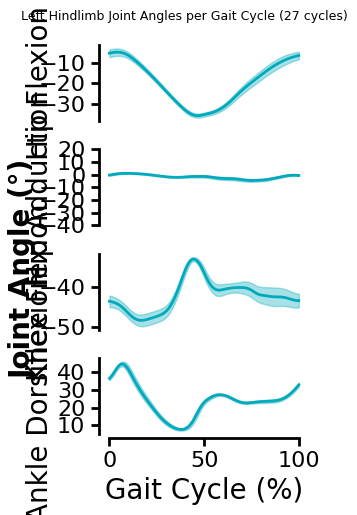

In [ ]:
# Plot average gait cycle profiles for left hip (2 DOFs), knee, and ankle
# Hip DOF qpos indices: abduct=14, extend=15, knee=16, ankle=17

# Y-axis limits for each joint (degrees). Set to None for auto-scaling.
Y_LIMITS = {
    15: None,  # Hip Flexion
    14: (-40, 20),  # Hip Adduction
    16: None,  # Knee Flexion
    17: None,  # Ankle Dorsiflexion
}

# Font / line styling (matched to plot_kid_results.ipynb)
LABEL_FONTSIZE = 20
TICK_LABELSIZE = 16
TICK_WIDTH = 2
TICK_LENGTH = 6
SPINE_WIDTH = 2

hip_extra_indices = [14]
for qpos_idx in hip_extra_indices:
    if qpos_idx not in joint_cycle_stats:
        cycles = []
        for cycle_start, cycle_end in gait_cycles:
            segment = qpos_all[cycle_start:cycle_end, qpos_idx]
            normalised = normalize_to_gait_percentage(segment, cycle_end - cycle_start)
            shift = PHASE_OFFSETS.get(qpos_idx, 0)
            if shift != 0:
                normalised = np.roll(normalised, int(round(shift)))
            cycles.append(normalised)
        cycles_arr = np.array(cycles)
        if CONVERT_TO_DEGREES:
            cycles_arr = np.degrees(cycles_arr)
        joint_cycle_stats[qpos_idx] = {
            "mean": np.mean(cycles_arr, axis=0),
            "std": np.std(cycles_arr, axis=0),
            "n_cycles": len(cycles),
            "raw_cycles": cycles_arr,
        }

left_indices = [15, 14, 16, 17]
left_titles = [
    "Hip Flexion",
    "Hip Adduction",
    "Knee Flexion",
    "Ankle Dorsiflexion",
]

n_rows = len(left_indices)
fig, axes = plt.subplots(n_rows, 1, figsize=(3, 5), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = tuple(c / 255 for c in (0, 170, 188))
rollout_shade_alpha = 0.35

for row, (qpos_idx, joint_title) in enumerate(zip(left_indices, left_titles)):
    ax = axes[row]
    stats = joint_cycle_stats[qpos_idx]
    mean = stats["mean"]
    std = stats["std"]

    ax.plot(gait_percentage, mean, color=rollout_color, linewidth=2)
    ax.fill_between(
        gait_percentage,
        mean - std,
        mean + std,
        color=rollout_color,
        alpha=rollout_shade_alpha,
    )

    if Y_LIMITS.get(qpos_idx) is not None:
        ax.set_ylim(*Y_LIMITS[qpos_idx])
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(10))

    ax.set_ylabel(joint_title, fontsize=LABEL_FONTSIZE)
    ax.yaxis.set_label_coords(-0.22, 0.5)  # align all y-labels at same x
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=TICK_LABELSIZE,
        width=TICK_WIDTH,
        length=TICK_LENGTH,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(SPINE_WIDTH)
    ax.grid(False)

    if row < n_rows - 1:
        ax.spines["bottom"].set_visible(False)
        ax.tick_params(bottom=False, labelbottom=False)
        ax.spines["left"].set_position(("outward", 1))
    else:
        ax.spines["bottom"].set_bounds(0, 100)
        ax.spines["left"].set_position(("outward", 1))
        ax.spines["bottom"].set_position(("outward", 3))
        ax.set_xlabel("Gait Cycle (%)", fontsize=LABEL_FONTSIZE)

angle_unit = "\u00b0" if CONVERT_TO_DEGREES else "rad"
fig.text(
    -0.08,
    0.5,
    f"Joint Angle ({angle_unit})",
    va="center",
    rotation="vertical",
    fontsize=LABEL_FONTSIZE,
    fontweight="bold",
)

n = joint_cycle_stats[left_indices[0]]["n_cycles"]
fig.suptitle(
    f"Left Hindlimb Joint Angles per Gait Cycle ({n} cycles)", fontsize=9, y=1.02
)

plt.tight_layout()
plt.subplots_adjust(left=0.22, top=0.95)
plt.show()

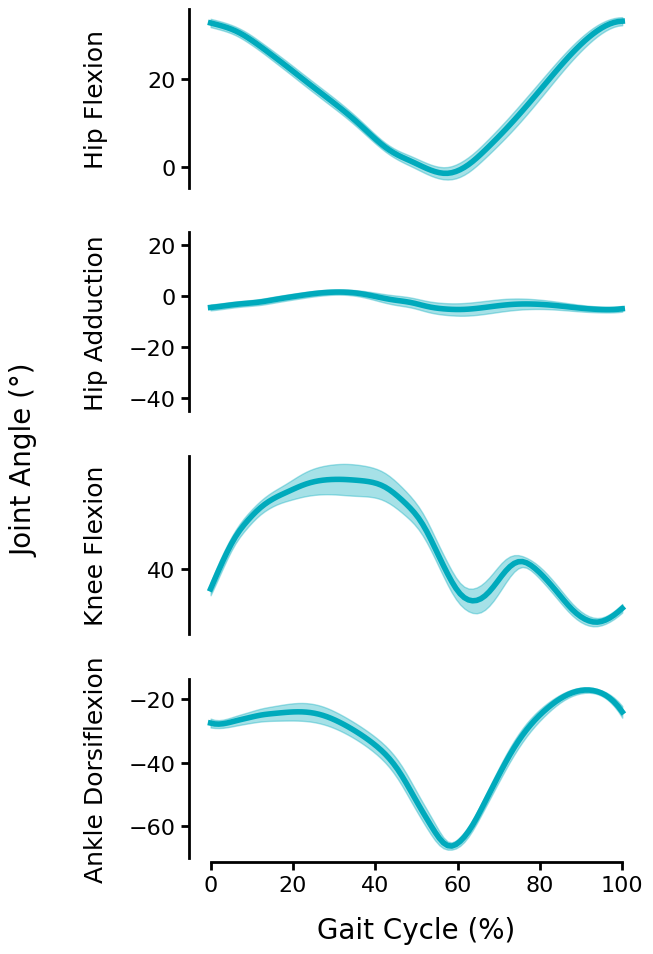

In [ ]:
# Plot average gait cycle profiles for right hip (2 DOFs), knee, and ankle
# Hip DOF qpos indices: abduct=20, extend=21, knee=22, ankle=23
#
# NOTE: Right-leg angles are negated to match left-leg / standard anatomical
# convention. This is necessary because the MuJoCo XML defines right-leg joint
# axes with opposite signs to the left leg for bilateral symmetry, e.g.:
#   hip_L_abduct   axis=( 1, 0,  0)  vs  hip_R_abduct   axis=(-1, 0, 0)
#   knee_L         axis=( 0.5,-1, 0)  vs  knee_R         axis=(-0.5,-1, 0)
#   ankle_L        axis=(-0.3, 1, 0)  vs  ankle_R        axis=( 0.3, 1, 0)
NEGATE_RIGHT = True

# Y-axis limits for each joint (degrees). Set to None for auto-scaling.
Y_LIMITS = {
    21: None,  # Hip Flexion
    20: (-45, 25),  # Hip Adduction
    22: None,  # Knee Flexion
    23: None,  # Ankle Dorsiflexion
}

# Font / line styling (matched to plot_kid_results.ipynb)
LABEL_FONTSIZE = 20
JOINTNAME_FONTSIZE = 18
TICK_LABELSIZE = 16
TICK_WIDTH = 2
TICK_LENGTH = 6
SPINE_WIDTH = 2

hip_extra_indices_R = [20]
for qpos_idx in hip_extra_indices_R:
    if qpos_idx not in joint_cycle_stats:
        cycles = []
        for cycle_start, cycle_end in gait_cycles:
            segment = qpos_all[cycle_start:cycle_end, qpos_idx]
            normalised = normalize_to_gait_percentage(segment, cycle_end - cycle_start)
            shift = PHASE_OFFSETS.get(qpos_idx, 0)
            if shift != 0:
                normalised = np.roll(normalised, int(round(shift)))
            cycles.append(normalised)
        cycles_arr = np.array(cycles)
        if CONVERT_TO_DEGREES:
            cycles_arr = np.degrees(cycles_arr)
        joint_cycle_stats[qpos_idx] = {
            "mean": np.mean(cycles_arr, axis=0),
            "std": np.std(cycles_arr, axis=0),
            "n_cycles": len(cycles),
            "raw_cycles": cycles_arr,
        }

right_indices = [21, 20, 22, 23]
right_titles = [
    "Hip Flexion",
    "Hip Adduction",
    "Knee Flexion",
    "Ankle Dorsiflexion",
]

n_rows = len(right_indices)
fig, axes = plt.subplots(n_rows, 1, figsize=(6, 10), sharex=True)
gait_percentage = np.linspace(0, 100, 100)

rollout_color = tuple(c / 255 for c in (0, 170, 188))
rollout_shade_alpha = 0.35
global_sign = -1.0 if NEGATE_RIGHT else 1.0

for row, (qpos_idx, joint_title) in enumerate(zip(right_indices, right_titles)):
    ax = axes[row]
    stats = joint_cycle_stats[qpos_idx]
    mean = global_sign * stats["mean"]
    std = stats["std"]

    ax.plot(gait_percentage, mean, color=rollout_color, linewidth=4)
    ax.fill_between(
        gait_percentage,
        mean - std,
        mean + std,
        color=rollout_color,
        alpha=rollout_shade_alpha,
    )

    if Y_LIMITS.get(qpos_idx) is not None:
        ax.set_ylim(*Y_LIMITS[qpos_idx])
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(20))

    ax.set_ylabel(joint_title, fontsize=JOINTNAME_FONTSIZE)
    ax.yaxis.set_label_coords(-0.18, 0.5)  # align all y-labels at same x
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=TICK_LABELSIZE,
        width=TICK_WIDTH,
        length=TICK_LENGTH,
    )
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_linewidth(SPINE_WIDTH)
    ax.grid(False)

    if row < n_rows - 1:
        ax.spines["bottom"].set_visible(False)
        ax.tick_params(bottom=False, labelbottom=False)
        ax.spines["left"].set_position(("outward", 1))
    else:
        ax.spines["bottom"].set_bounds(0, 100)
        ax.spines["left"].set_position(("outward", 1))
        ax.spines["bottom"].set_position(("outward", 3))
        ax.set_xlabel("Gait Cycle (%)", fontsize=LABEL_FONTSIZE, labelpad=15)

angle_unit = "\u00b0" if CONVERT_TO_DEGREES else "rad"
fig.text(
    -0.08,
    0.5,
    f"Joint Angle ({angle_unit})",
    va="center",
    rotation="vertical",
    fontsize=LABEL_FONTSIZE,
)

n = joint_cycle_stats[right_indices[0]]["n_cycles"]

plt.tight_layout()
plt.subplots_adjust(left=0.22, top=0.95, hspace=0.25)
plt.show()